# FPL exploratory data analysis

Use Notebook 1's prepared player, team and fixture tables. Validate historical starter lists,
repair the all-zero start blocks in a separate `starts_eda` field, and mark the affected ICT
cells as unavailable. Preserve all player-fixture records and defensive measurements.

The historical seasons are complete; the current snapshot covers fixtures through GW10.
This notebook explores recorded participation and activity before later modelling. The
[EDA plan](../docs/02_eda_plan.md) defines scope; the
[notebook conventions](../docs/notebook_style.md) define structure and code style.

## Findings and reading path

- **Repeated historical patterns:** appearance points are the largest average source in all
  16 season/position groups. Clean sheets are the largest remaining source for keepers and
  defenders; attacking returns fill that role for midfielders and forwards in all four seasons.
- **Team balance matters:** within-season points correlate strongly with goal difference
  (Spearman 0.91–0.96). The xGD relationship also repeats (0.76–0.91), using points from the
  same covered fixtures. These are descriptive associations, not causal or predictive effects.
- **Captured current progress:** through GW10, Arsenal have 27 results-based points and the
  lowest xGA (7.63). Bournemouth's points per match rise from 0.6 to 2.4 between their first
  and latest five fixtures; City's fall from 3.0 to 1.2. Player returns below are linked to
  current-club form and the opponents' records available before each match.
- **Rankings remain uncertain:** all eight position/period comparisons between the top two
  observed points-per-90 players have 95% gameweek-resampling gap ranges spanning zero.
  A displayed rank is an observed ordering, not an established difference in ability.

For a short route, read [historical patterns](#Patterns-across-historical-seasons),
[current team context](#Current-team-and-opponent-context) and
[ranking stability](#Ranking-stability). The detailed
[player report](#Current-player-progress) and
[preparation checks](#Data-import) retain the evidence behind those conclusions.

## Data import

Use the same project paths and display settings as Notebook 1. The cached FotMob matches
are used only for identity evidence and starter lists; no additional activity statistics
are collected.

In [1]:
from pathlib import Path
from hashlib import sha256
import json
import os
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache/matplotlib"))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

from src.data_preparation import MATCH_KEY, require_keys
from src.eda_preparation import (
    DEFENSIVE_FIELDS, ICT_FIELDS, TEAM_FIXTURE_KEY, build_start_bridges,
    load_lineup_starters, mask_ict_gaps, player_profiles, profile_team_starts,
    repair_starts, team_activity,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

PROCESSED_DIR = PROJECT_ROOT / "data/processed"
FOTMOB_CACHE = PROJECT_ROOT / "data/epl-premier-league-dataset/raw_data/sofascore"
FOTMOB_CACHE /= "sofascore_matches_cache.tar.gz"
POSITION_ORDER = ["GK", "DEF", "MID", "FWD"]

## Prepared table inventory

Load only Notebook 1's saved tables, audits and manifest. Record their checksums before
creating analytical copies. Player summaries without IDs remain separate from fixture records.

In [2]:
input_paths = [PROCESSED_DIR / f"fpl_{name}" for name in (
    "tables.pkl", "audits.pkl", "manifest.json",
)]
source_hashes = {path.name: sha256(path.read_bytes()).hexdigest() for path in input_paths}
tables = pd.read_pickle(input_paths[0])
source_audits = pd.read_pickle(input_paths[1])
source_manifest = json.loads(input_paths[2].read_text())
snapshot_metadata = tables["current_snapshot_metadata"].iloc[0]
CURRENT_SEASON = snapshot_metadata.season
LAST_GW = int(snapshot_metadata.last_checked_GW)

table_inventory = pd.DataFrame([
    {"table": name, "rows": len(frame), "columns": len(frame.columns)}
    for name, frame in tables.items()
])
display(table_inventory)
display(tables["current_snapshot_metadata"][[
    "season", "retrieved_at_utc", "last_checked_GW", "finished_fixtures",
]])

,table,rows,columns
0,player_matches,113260,58
1,player_registry,3268,5
2,player_summaries,3268,22
3,teams,80,24
4,fixtures,1520,19
5,current_players,672,112
6,current_teams,20,25
7,current_fixtures,380,20
8,current_events,38,32
9,current_snapshot_metadata,1,13


,season,retrieved_at_utc,last_checked_GW,finished_fixtures
0,2026_2027,2026-11-10 21:06:23.051534+00:00,10,100


## Working tables and keys

| Table | Row level | Key |
|---|---|---|
| Player matches | Player in one fixture | `season, fpl_player_id, fpl_fixture_id` |
| Fixtures | Fixture | `season, fpl_fixture_id` |
| Teams | Team-season reference | `season, fpl_team_id` |
| Current players | Player at collection time | `season, fpl_player_id` |

Stack compatible historical and current records. Keep zero minutes and use only completed
fixtures for activity analysis. Team reference counters and strength fields are not used as
measured team performance.

In [3]:
source_matches = pd.concat([
    tables["player_matches"], tables["current_player_matches"],
], ignore_index=True, sort=False)
working_fixtures = pd.concat([
    tables["fixtures"], tables["current_fixtures"],
], ignore_index=True, sort=False)
working_teams = pd.concat([
    tables["teams"], tables["current_teams"],
], ignore_index=True, sort=False)[["season", "fpl_team_id", "name", "short_name"]]

require_keys(source_matches, MATCH_KEY, "source player fixtures")
require_keys(working_fixtures, ["season", "fpl_fixture_id"], "fixtures")
require_keys(working_teams, ["season", "fpl_team_id"], "teams")
fixture_flags = working_fixtures.groupby("season").agg(
    scheduled=("fpl_fixture_id", "size"), completed=("finished", "sum"),
)
display(fixture_flags)

,scheduled,completed
season,,
2022_2023,380,380
2023_2024,380,380
2024_2025,380,380
2025_2026,380,380
2026_2027,380,100


## Start coverage before repair

A complete team-fixture should contain eleven starts. An all-zero block with positive
playing time is a coverage gap, not evidence that everyone was a substitute. This check
identifies the affected blocks without selecting a season or fixture by hand.

In [4]:
starts_before = profile_team_starts(source_matches)
start_coverage = starts_before.groupby("season").agg(
    team_fixtures=("starters", "size"),
    eleven_starts=("starters", lambda values: values.eq(11).sum()),
    zero_starts=("starters", lambda values: values.eq(0).sum()),
)
display(start_coverage)

,team_fixtures,eleven_starts,zero_starts
season,,,
2022_2023,760,488,272
2023_2024,760,760,0
2024_2025,760,760,0
2025_2026,760,760,0
2026_2027,200,200,0


## FotMob identity bridges

Reuse Notebook 1's matching rules: reviewed names, shared fixtures and the same match-time
club. Numeric IDs from different providers are not interchangeable. The bridges remain in
audits; the working records keep native FPL keys.

In [5]:
start_bridges = build_start_bridges(tables, FOTMOB_CACHE)
identity_coverage = start_bridges["players"].groupby([
    "season", "mapping_status",
]).size().rename("players").reset_index()
display(identity_coverage)

,season,mapping_status,players
0,2022_2023,matched,691
1,2022_2023,no_shared_fixture_name_match,86
2,2022_2023,unusable_fotmob_source_id,1
3,2023_2024,matched,723
4,2023_2024,no_shared_fixture_name_match,141
5,2023_2024,unusable_fotmob_source_id,1
6,2024_2025,matched,678
7,2024_2025,no_shared_fixture_name_match,106
8,2025_2026,matched,674
9,2025_2026,no_shared_fixture_name_match,167


## Validate lineups and repair starts

Read explicit starter lists from completed cached matches. Require eleven unique mapped
starters per club and validate against credible FPL starts before repairing the zero blocks.
Preserve original `starts`; use nullable `starts_eda` in every analysis below. Unused roster
players need not have a FotMob identity when all eleven starters are positively identified.

In [6]:
lineups = load_lineup_starters(FOTMOB_CACHE, start_bridges["fixture_lookup"])
start_repair = repair_starts(tables["player_matches"], lineups, start_bridges)
assert start_repair["starter_review"].empty
assert start_repair["validation"].compared_rows.sum() == (
    len(tables["player_matches"]) - len(start_repair["audit"])
)

current_matches = tables["current_player_matches"].assign(
    starts_eda=lambda frame: frame.starts.astype("Int64"),
)
working_player_matches = pd.concat([
    start_repair["matches"], current_matches,
], ignore_index=True, sort=False)
repair_summary = start_repair["audit"].groupby("season").agg(
    fixtures=("fpl_fixture_id", "nunique"), checked_records=("changed", "size"),
    corrected_starts=("changed", "sum"),
)
display(start_repair["validation"])
display(repair_summary)

,compared_rows,disagreements
season,,
2022_2023,18014,0
2023_2024,29725,0
2024_2025,27283,0
2025_2026,29747,0


,fixtures,checked_records,corrected_starts
season,,,
2022_2023,136,8491,2992


## Unavailable ICT cells

Set the four ICT fields to NA only where all four team totals are zero despite recorded
playing time. Keep other values, including genuine zeros, and do not reconstruct these
indices. No rows or defensive counts are removed.

In [7]:
ict_mask = mask_ict_gaps(working_player_matches)
working_player_matches = ict_mask["matches"]
ict_coverage = ict_mask["gaps"].groupby("season").agg(
    affected_team_fixtures=("fpl_team_id", "size"),
    affected_fixtures=("fpl_fixture_id", "nunique"),
)
ict_coverage["masked_rows"] = ict_mask["audit"].groupby("season").size()
ict_coverage["masked_cells"] = ict_coverage.masked_rows * len(ICT_FIELDS)
display(ict_coverage)

,affected_team_fixtures,affected_fixtures,masked_rows,masked_cells
season,,,,
2022_2023,30,15,1147,4588
2023_2024,1,1,36,144


## Validate the working copy

Check native keys, row order, eleven repaired starts per team-fixture and exact preservation
of all fields outside the ICT mask. The defensive records and original start indicators must
remain identical to the source. Confirm that the original saved inputs are unchanged.

In [8]:
require_keys(working_player_matches, MATCH_KEY, "EDA player fixtures")
assert len(working_player_matches) == len(source_matches)
unchanged_columns = source_matches.columns.difference(ICT_FIELDS)
pd.testing.assert_frame_equal(
    working_player_matches[unchanged_columns], source_matches[unchanged_columns],
)
pd.testing.assert_frame_equal(
    working_player_matches[DEFENSIVE_FIELDS], source_matches[DEFENSIVE_FIELDS],
)
starts_after = profile_team_starts(working_player_matches, "starts_eda")
assert starts_after.starters.eq(11).all()
masked_rows = pd.MultiIndex.from_frame(working_player_matches[MATCH_KEY]).isin(
    pd.MultiIndex.from_frame(ict_mask["audit"][MATCH_KEY])
)
assert working_player_matches.loc[masked_rows, ICT_FIELDS].isna().all().all()
pd.testing.assert_frame_equal(
    working_player_matches.loc[~masked_rows, ICT_FIELDS].astype("Float64"),
    source_matches.loc[~masked_rows, ICT_FIELDS].astype("Float64"),
)
assert source_hashes == {
    path.name: sha256(path.read_bytes()).hexdigest() for path in input_paths
}
display(starts_after.groupby("season").agg(
    team_fixtures=("starters", "size"), minimum_starters=("starters", "min"),
    maximum_starters=("starters", "max"),
))

,team_fixtures,minimum_starters,maximum_starters
season,,,
2022_2023,760,11,11
2023_2024,760,11,11
2024_2025,760,11,11
2025_2026,760,11,11
2026_2027,200,11,11


## Minutes and participation

Zero minutes are valid recorded observations. Keep them when describing participation;
use positive-minute appearances for on-pitch activity. These distributions pool fixture
records, not equally weighted player averages. A missing eligibility history prevents us
from treating every observed-record rate as a selection probability. One-minute bins keep
zero-minute records separate in the figure.

In [9]:
season_coverage = working_player_matches.groupby("season").agg(
    records=("minutes", "size"), players=("fpl_player_id", "nunique"),
    fixtures=("fpl_fixture_id", "nunique"),
    appearances=("minutes", lambda values: values.gt(0).sum()),
    zero_minutes=("minutes", lambda values: values.eq(0).sum()),
)
season_coverage["zero_minute_share"] = season_coverage.zero_minutes / season_coverage.records
played_matches = working_player_matches.loc[working_player_matches.minutes.gt(0)]
display(season_coverage)

,records,players,fixtures,appearances,zero_minutes,zero_minute_share
season,,,,,,
2022_2023,26505,778,380,11345,15160,0.5720
2023_2024,29725,865,380,11384,18341,0.6170
2024_2025,27283,784,380,11567,15716,0.5760
2025_2026,29747,841,380,11492,18255,0.6137
2026_2027,6562,672,100,3084,3478,0.5300


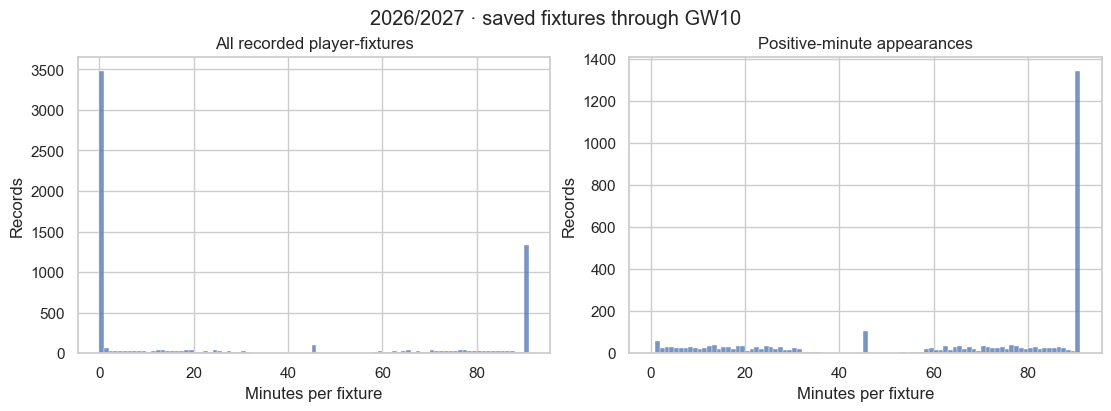

In [10]:
current = working_player_matches.loc[working_player_matches.season.eq(CURRENT_SEASON)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, frame, title in zip(axes, [current, current.loc[current.minutes.gt(0)]], [
    "All recorded player-fixtures", "Positive-minute appearances",
]):
    sns.histplot(data=frame, x="minutes", bins=range(0, 92), ax=ax)
    ax.set(title=title, xlabel="Minutes per fixture", ylabel="Records")
fig.suptitle(f"{CURRENT_SEASON.replace('_', '/')} · saved fixtures through GW{LAST_GW}")
plt.show()

## Player profiles

Use one row per player-season and FPL position. Compute each activity rate as summed activity
per 90 valid minutes, retaining the metric-specific exposure. Do not average fixture-level
per-90 rates. Players with no exposure have NA rates; real zero activity remains zero.

Keep full-season profiles separate from GW1–10 profiles. Equal gameweek windows can contain
different fixture counts because of postponements. The 450-minute comparison cutoff is an
explicit exploratory choice, not a guarantee of statistical reliability.

In [11]:
profiles = player_profiles(working_player_matches)
gw10_matches = working_player_matches.loc[working_player_matches.GW.le(10)]
profiles_gw10 = player_profiles(gw10_matches)
cohort = profiles_gw10.loc[profiles_gw10.minutes.ge(450)]
cohort_sizes = cohort.groupby(["season", "position"]).size().unstack(fill_value=0)
display(cohort_sizes.reindex(columns=POSITION_ORDER))
display(profiles_gw10.loc[profiles_gw10.season.eq(CURRENT_SEASON), [
    "name", "position", "minutes", "starts", "creativity_per90", "creativity_minutes",
]].head().reset_index(drop=True))

position,GK,DEF,MID,FWD
season,,,,
2022_2023,20,74,93,17
2023_2024,20,81,89,22
2024_2025,21,79,92,21
2025_2026,21,80,94,19
2026_2027,21,81,86,20


,name,position,minutes,starts,creativity_per90,creativity_minutes
0,David Raya Martín,GK,900,10,0.0200,900
1,Kepa Arrizabalaga Revuelta,GK,0,0,<NA>,<NA>
2,Illan Meslier,GK,0,0,<NA>,<NA>
3,Gabriel dos Santos Magalhães,DEF,900,10,4.7000,900
4,Jurriën Timber,DEF,335,3,23.9104,335


### Positional activity distributions

Compare outfield players within position. Recovery volume describes activity and opportunity;
it does not establish defensive quality. The current comparison contains only saved GW1–10
records and players with at least 450 minutes.

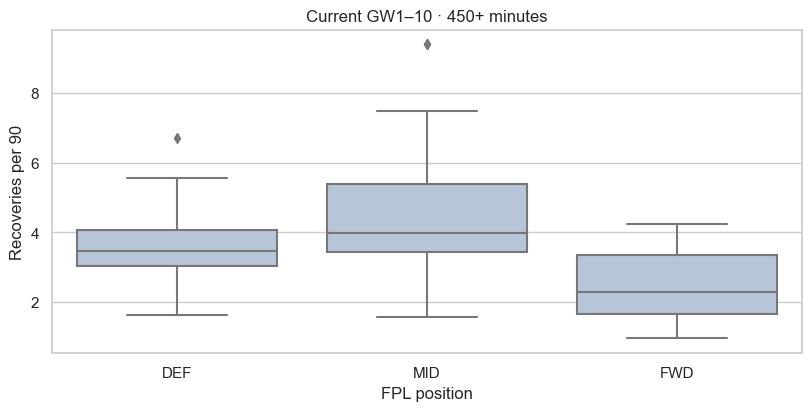

In [12]:
current_cohort = cohort.loc[cohort.season.eq(CURRENT_SEASON) & cohort.position.ne("GK")]
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
sns.boxplot(
    data=current_cohort, x="position", y="recoveries_per90",
    order=POSITION_ORDER[1:], color="lightsteelblue", ax=ax,
)
ax.set(title="Current GW1–10 · 450+ minutes", xlabel="FPL position", ylabel="Recoveries per 90")
plt.show()

## Team activity

Start from the completed fixture calendar, with one row per team-fixture. Join additive
player activity using match-time club IDs. Ignore placeholder reference counters and keep
missing team ICT totals missing. Collective action counts measure workload, not efficiency.
No new FotMob team or activity statistics are added.

In [13]:
team_matches = team_activity(working_player_matches, working_fixtures, working_teams)
assert len(team_matches) == 2 * working_fixtures.finished.sum()
assert team_matches.starts.eq(11).all()
team_profiles = team_matches.groupby(["season", "fpl_team_id", "team"]).agg(
    fixtures=("fpl_fixture_id", "size"),
    appearances_per_fixture=("appearances", "mean"),
    tackles_per_fixture=("tackles", "mean"),
    recoveries_per_fixture=("recoveries", "mean"),
).reset_index()
display(team_profiles.loc[team_profiles.season.eq(CURRENT_SEASON)].head(10))

,season,fpl_team_id,team,fixtures,appearances_per_fixture,tackles_per_fixture,recoveries_per_fixture
80,2026_2027,1,Arsenal,10,15.8000,12.6000,46.2000
81,2026_2027,2,Aston Villa,10,15.8000,18.1000,42.3000
82,2026_2027,3,Bournemouth,10,15.8000,15.9000,52.6000
83,2026_2027,4,Brentford,10,15.7000,16.7000,50.8000
84,2026_2027,5,Brighton,10,15.5000,14.9000,44.6000
85,2026_2027,6,Chelsea,10,15.6000,16.6000,46.8000
86,2026_2027,7,Coventry City,10,15.4000,11.6000,42.9000
87,2026_2027,8,Crystal Palace,10,15.3000,21.0000,46.6000
88,2026_2027,9,Everton,10,14.8000,16.0000,50.2000
89,2026_2027,10,Fulham,10,15.5000,14.5000,45.8000


## Historical point production

Use the four completed seasons to understand the sources and variability of official FPL
points. Retain departed players as historical evidence. Keep season, position and measurement
source available for checks instead of repeating every leaderboard for every year.

The historical extension includes point production, player performance and team performance.
Current-player progress is presented separately after the historical report. Existing preparation diagnostics above are unchanged.

In [14]:
import numpy as np

from src.player_analysis import (
    COMPONENT_RULE, HISTORICAL_SEASONS, POINT_COMPONENTS, event_rates, expected_coverage,
    fit_expected_actual, performance_profiles, plot_expected_fit, point_associations,
    point_components, point_summary, rank_players,
)

BENCHMARK_SEASON = "2025_2026"
MIN_HISTORY_MINUTES = 900
POSITION_COLORS = dict(zip(POSITION_ORDER, sns.color_palette("deep", 4)))
historical_matches = working_player_matches.loc[
    working_player_matches.season.isin(HISTORICAL_SEASONS)
].copy()
assert not historical_matches.season.eq(CURRENT_SEASON).any()

from src.plot_annotations import (
    annotate_points, annotate_team_logos, leading_player_labels, team_logo_paths,
)

LABEL_ALIASES = {
    136: "Igor Thiago", 449: "Bruno Fernandes",
    249: "João Pedro", 72: "Marcos Senesi",
    5: "Gabriel Magalhães", 311: "Beto",
}
PRICE_LABEL_ALIASES = {
    365: "Nmecha", 100: "Jr. Kroupi", 311: "Beto", 698: "Okafor",
    418: "Doku", 417: "Cherki", 681: "Sesko", 5: "Gabriel",
    661: "Ekitike", 16: "Saka", 449: "Bruno", 430: "Haaland",
}

### Point distributions and denominators

Official points describe delivered output under the rules of their season. Show all recorded
player-fixtures separately from positive-minute appearances: non-appearances affect reliability,
and zero-minute card deductions remain valid records. The tables and figures below use fixtures,
not gameweek totals. Six-plus and ten-plus frequencies are observed rates, not forecasts.

records   mean  median     sd  q25    q75  zero_rate  \
scope       position                                                         
All records DEF         37673 1.0750  0.0000 2.2780    0 1.0000     0.6360   
            FWD         13263 1.3010  0.0000 2.6260    0 1.0000     0.5880   
            GK          12500 0.8290  0.0000 2.0040    0 0.0000     0.7620   
            MID         49824 1.2160  0.0000 2.3480    0 2.0000     0.5760   
Appearances DEF         15356 2.6370  1.0000 2.9350    1 4.0000     0.1060   
            FWD          5622 3.0680  2.0000 3.2930    1 4.7500     0.0290   
            GK           3083 3.3630  2.0000 2.7860    2 5.0000     0.0380   
            MID         21727 2.7880  2.0000 2.8740    1 3.0000     0.0280   

                      negative_rate  six_plus_rate  ten_plus_rate  
scope       position                                               
All records DEF              0.0100         0.0850         0.0120  
            FWD              0.0010         0.0810         0.0220  
            GK               0.0020         0.0610         0.0110  
            MID              0.0020         0.0610         0.0200  
Appearances DEF              0.0230         0.2090         0.0290  
            FWD              0.0020         0.1910         0.0510  
            GK               0.0070         0.2480         0.0430  
            MID              0.0040         0.1390         0.0460

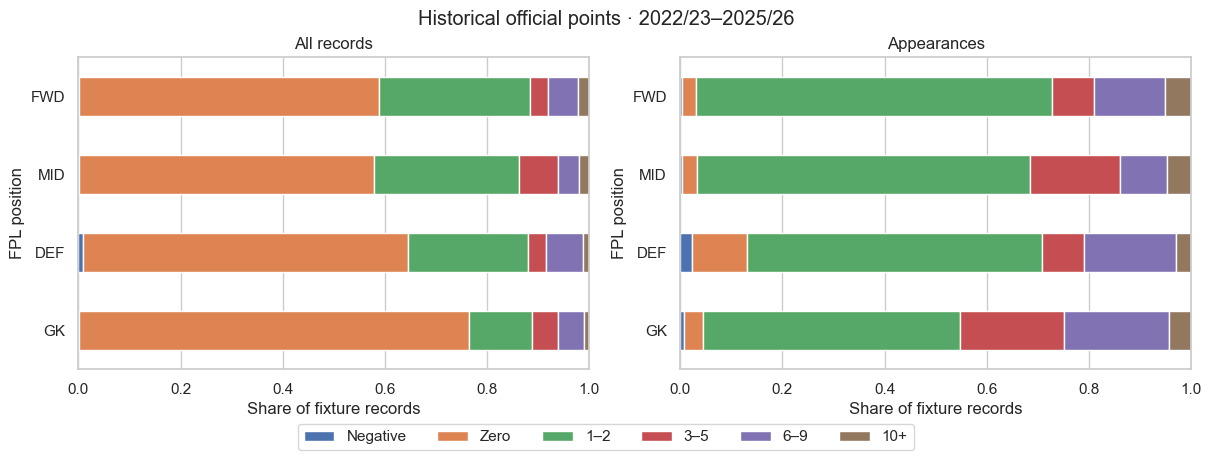

In [15]:
historical_point_summary = point_summary(historical_matches)
display(historical_point_summary.set_index(["scope", "position"]).round(3))

bands = [-np.inf, -.5, .5, 2.5, 5.5, 9.5, np.inf]
band_labels = ["Negative", "Zero", "1–2", "3–5", "6–9", "10+"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, frame, title in zip(axes, [historical_matches,
    historical_matches.loc[historical_matches.minutes.gt(0)]], ["All records", "Appearances"]):
    categories = pd.cut(frame.P_off.astype(float), bins=bands, labels=band_labels)
    shares = pd.crosstab(frame.position, categories, normalize="index")
    shares.reindex(POSITION_ORDER).plot.barh(stacked=True, ax=ax, legend=False)
    ax.set(title=title, xlabel="Share of fixture records", ylabel="FPL position", xlim=(0, 1))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=6)
fig.suptitle("Historical official points · 2022/23–2025/26")
plt.show()

All-record medians are zero in every position. Conditional on appearing, mean official points
are 2.64 for DEF, 2.79 for MID, 3.07 for FWD and 3.36 for GK. These pooled figures include short
cameos and different seasonal rules; they are not a position-quality ranking. Goalkeepers'
longer appearances help explain why their conditional average is higher.

### Account for the points

Calculate documented awards per fixture, including save floors and capped defensive rewards.
Goalkeepers' goal awards changed from six to ten in 2024/25; defensive rewards began in 2025/26.
Preserve awarded bonus rather than recomputing BPS. The original and adjusted point columns
remain unchanged. Any difference from official points stays in a separate residual.

Sources: [2024/25 scoring changes](https://www.premierleague.com/en/news/4059044),
[scoring rules](https://www.premierleague.com/es/news/4661029), and
[defensive scoring](https://www.premierleague.com/en/news/4361991/whats-new-in-202526-fantasy-defensive-contributions).

In [16]:
historical_components = point_components(historical_matches)
component_review = historical_components.loc[historical_components.official_residual.ne(0)]
assert historical_components[POINT_COMPONENTS].notna().all().all()
assert historical_components.P_off.equals(historical_matches.P_off)
assert historical_components.P_adj.equals(historical_matches.P_adj)
pd.testing.assert_series_equal(
    historical_components.documented_total + historical_components.official_residual,
    historical_matches.P_off, check_names=False,
)
component_validation = historical_components.groupby("season").agg(
    records=("P_off", "size"), official_points=("P_off", "sum"),
    documented_points=("documented_total", "sum"), residual=("official_residual", "sum"),
)
display(component_validation)
display(component_review[MATCH_KEY + ["name", "minutes", "P_off", "official_residual"]])

,records,official_points,documented_points,residual
season,,,,
2022_2023,26505,31724,31724,0
2023_2024,29725,31271,31271,0
2024_2025,27283,31290,31291,-1
2025_2026,29747,34382,34382,0


,season,fpl_player_id,fpl_fixture_id,name,minutes,P_off,official_residual
71993,2024_2025,123,239,Evan Ferguson,17,0,-1


The single residual is Ferguson's documented 2024/25 record: corrected playing time implies
one appearance point, while the preserved official export has zero. This remains visible;
it is not silently reassigned to another component. `P_adj` already contains the reviewed
correction. All other historical records reconcile under this component calculation.

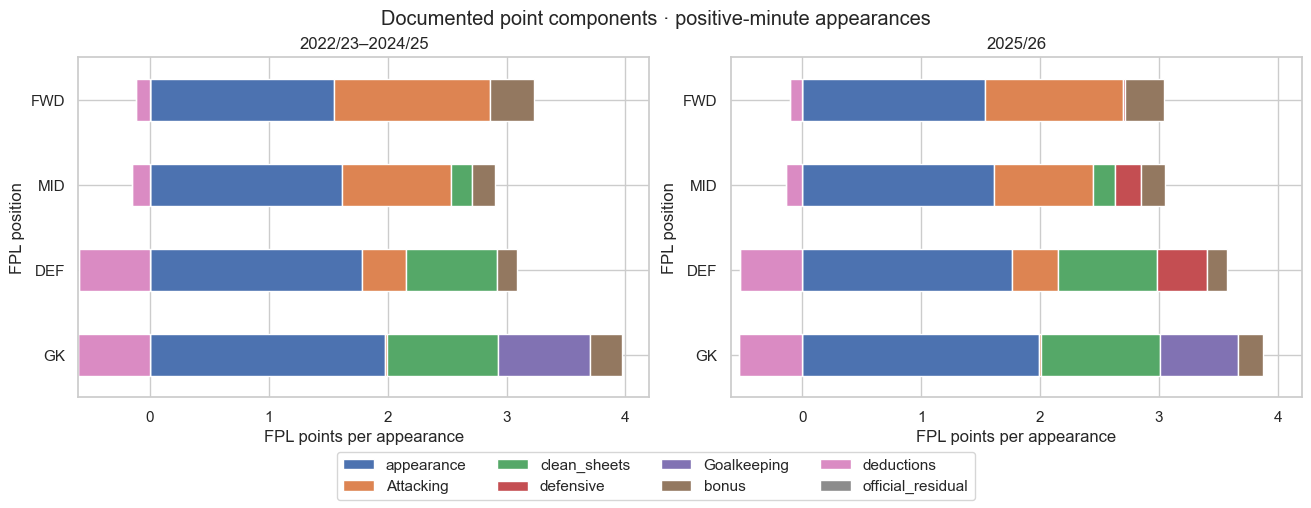

In [17]:
component_appearances = historical_components.loc[historical_components.minutes.gt(0)].copy()
component_appearances["period"] = np.where(
    component_appearances.season.eq(BENCHMARK_SEASON), "2025/26", "2022/23–2024/25",
)
component_appearances["Attacking"] = component_appearances.goals + component_appearances.assists
component_appearances["Goalkeeping"] = (
    component_appearances.saves + component_appearances.penalty_saves
)
component_fields = ["appearance", "Attacking", "clean_sheets", "defensive", "Goalkeeping",
                    "bonus", "deductions", "official_residual"]
component_means = component_appearances.groupby(["period", "position"])[component_fields].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, layout="constrained")
for ax, period in zip(axes, ["2022/23–2024/25", "2025/26"]):
    component_means.loc[period].reindex(POSITION_ORDER).plot.barh(
        stacked=True, ax=ax, legend=False,
    )
    ax.set(title=period, xlabel="FPL points per appearance", ylabel="FPL position")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4)
fig.suptitle("Documented point components · positive-minute appearances")
plt.show()

Appearance points are the largest mean component in every position in 2025/26. Defenders
average 0.42 defensive-contribution points per appearance, versus 0.83 clean-sheet points;
goalkeepers average 0.58 save points. These sources can contribute without an attacking
return. The period comparison also reflects different players, opportunities and rules.

### Recurring sources and seasonal sensitivity

Compare the frequency of contributing events among appearances. Earlier defensive threshold
hits are reconstructed estimates, not official awards from those seasons. Blank heatmap cells
mean the measure does not apply to that position. More defensive activity or saves can reflect
workload rather than quality. Changes between periods are descriptive, not causal estimates.

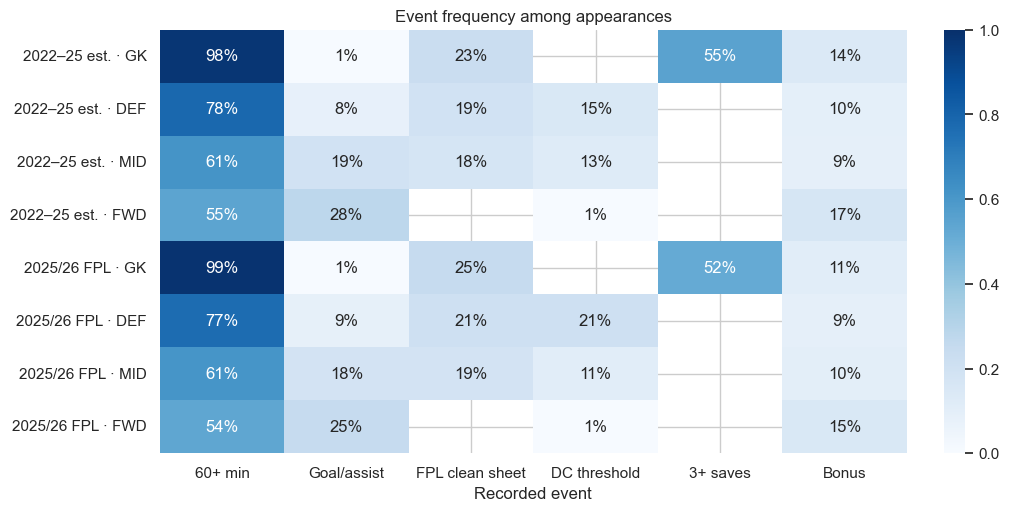

In [18]:
historical_event_rates = event_rates(historical_matches)
event_fields = ["sixty_plus", "attacking_return", "clean_sheet", "defensive_hit",
                "save_reward", "bonus_award"]
event_plot = historical_event_rates.copy()
event_plot["period"] = event_plot.period.replace({
    "2022/23–2024/25 reconstructed DC": "2022–25 est.", "2025/26 supplied DC": "2025/26 FPL",
})
event_plot["position"] = pd.Categorical(
    event_plot.position, categories=POSITION_ORDER, ordered=True,
)
event_plot = event_plot.sort_values(["period", "position"])
event_plot["label"] = event_plot.period + " · " + event_plot.position.astype("string")
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
event_labels = ["60+ min", "Goal/assist", "FPL clean sheet", "DC threshold", "3+ saves", "Bonus"]
event_values = event_plot.set_index("label")[event_fields].astype(float)
sns.heatmap(event_values.set_axis(event_labels, axis=1), annot=True,
            fmt=".0%", vmin=0, vmax=1, cmap="Blues", ax=ax)
ax.set(title="Event frequency among appearances", xlabel="Recorded event", ylabel="")
plt.show()

In [19]:
point_source_sensitivity = historical_matches.loc[historical_matches.minutes.gt(0)].groupby([
    "season", "position",
]).agg(appearances=("minutes", "size"), official_mean=("P_off", "mean"),
       adjusted_mean=("P_adj", "mean"))
point_source_sensitivity["adjustment_per_appearance"] = (
    point_source_sensitivity.adjusted_mean - point_source_sensitivity.official_mean
)
display(point_source_sensitivity)

appearances  official_mean  adjusted_mean  \
season    position                                              
2022_2023 DEF              3776         2.6337         2.9007   
          FWD              1477         2.9993         3.0088   
          GK                770         3.6104         3.6104   
          MID              5322         2.7384         3.0413   
2023_2024 DEF              3843         2.4197         2.7054   
          FWD              1445         3.1377         3.1529   
          GK                776         3.1946         3.1946   
          MID              5320         2.8126         3.0776   
2024_2025 DEF              3787         2.4317         2.7792   
          FWD              1272         3.2075         3.2209   
          GK                770         3.3065         3.3065   
          MID              5738         2.6936         2.8982   
2025_2026 DEF              3950         3.0476         3.0476   
          FWD              1428         2.9454         2.9454   
          GK                767         3.3429         3.3429   
          MID              5347         2.9128         2.9128   

                    adjustment_per_appearance  
season    position                             
2022_2023 DEF                          0.2669  
          FWD                          0.0095  
          GK                           0.0000  
          MID                          0.3029  
2023_2024 DEF                          0.2857  
          FWD                          0.0152  
          GK                           0.0000  
          MID                          0.2650  
2024_2025 DEF                          0.3475  
          FWD                          0.0134  
          GK                           0.0000  
          MID                          0.2046  
2025_2026 DEF                          0.0000  
          FWD                          0.0000  
          GK                           0.0000  
          MID                          0.0000

### Expected-stat coverage and associations

The first 136 fixtures of 2022/23 have all-zero xG and xA despite recorded playing time.
Flag these blocks as unavailable for expected-stat analysis without altering the working
records. Partial expected totals must not be compared with full-season actual totals.

The association check therefore uses 2023/24–2025/26, split by season and outfield position, with at least
900 minutes and complete exposure for each measure. Rank correlations describe same-window
relationships with points per 90; they are not forecasting importance or evidence of causation.
Goalkeepers are assessed through their save and clean-sheet profiles rather than sparse attacking measures.

In [20]:
historical_expected_coverage = expected_coverage(historical_matches)
coverage_summary = historical_expected_coverage.groupby("season").agg(
    fixtures=("fpl_fixture_id", "size"),
    suspect_zero_blocks=("suspect_zero_block", "sum"),
)
historical_performance = performance_profiles(historical_matches, historical_expected_coverage)
historical_associations = point_associations(historical_performance, MIN_HISTORY_MINUTES)
display(coverage_summary)
historical_identities = historical_matches.groupby(["season", "fpl_player_id"]).ngroups
assert len(historical_performance) == historical_identities

,fixtures,suspect_zero_blocks
season,,
2022_2023,380,136
2023_2024,380,0
2024_2025,380,0
2025_2026,380,0


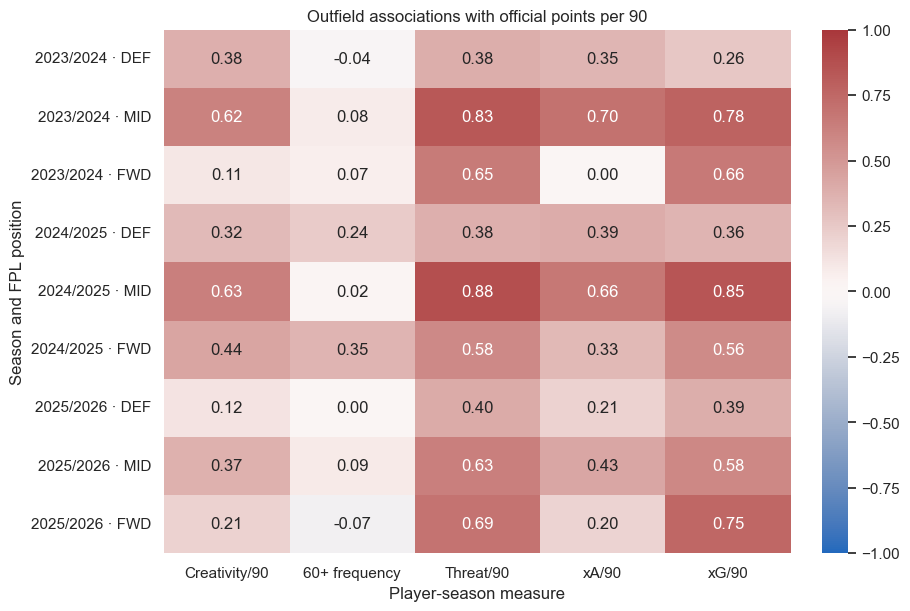

,min,max
metric,,
creativity_per90,30,153
sixty_plus_rate,30,153
threat_per90,30,153
xa_per90,30,153
xg_per90,30,153


In [21]:
association_matrix = historical_associations.pivot(
    index=["season", "position"], columns="metric", values="spearman",
)
row_order = pd.MultiIndex.from_product([
    sorted(historical_associations.season.unique()), POSITION_ORDER[1:],
], names=["season", "position"])
association_matrix = association_matrix.reindex(row_order)
association_matrix.columns = ["Creativity/90", "60+ frequency", "Threat/90", "xA/90", "xG/90"]
association_matrix.index = [season.replace("_", "/") + " · " + pos
                            for season, pos in association_matrix.index]
fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
sns.heatmap(association_matrix, annot=True, fmt=".2f", vmin=-1, vmax=1,
            center=0, cmap="vlag", ax=ax)
ax.set(title="Outfield associations with official points per 90",
       xlabel="Player-season measure", ylabel="Season and FPL position")
plt.show()
display(historical_associations.groupby("metric").players.agg(["min", "max"]))

## 2025/26 player performance

Use the latest complete season as the main historical player benchmark. Earlier players remain
in the exported historical evidence, even if they have since left the league. The comparison
cohort contains players with at least 900 minutes; lower-minute records are retained separately.
The report ranks observed production and rates, not current availability or future potential.

In [22]:
benchmark = historical_performance.loc[
    historical_performance.season.eq(BENCHMARK_SEASON)
].copy()
benchmark_cohort = benchmark.loc[benchmark.minutes.ge(MIN_HISTORY_MINUTES)]
cohort_review = benchmark.groupby("position").agg(
    players=("fpl_player_id", "size"),
    with_minutes=("minutes", lambda values: values.gt(0).sum()),
    comparison_cohort=("minutes", lambda values: values.ge(MIN_HISTORY_MINUTES).sum()),
)
display(cohort_review.reindex(POSITION_ORDER))
lower_minutes = benchmark.loc[benchmark.minutes.between(1, MIN_HISTORY_MINUTES - 1)]
display(lower_minutes.nlargest(5, "official_points")[[
    "name", "position", "minutes", "official_points", "official_points_per90",
]].reset_index(drop=True))

,players,with_minutes,comparison_cohort
position,,,
GK,97,40,24
DEF,270,183,128
MID,379,248,153
FWD,95,66,34


,name,position,minutes,official_points,official_points_per90
0,William Osula,FWD,805,76,8.4969
1,Estêvão Almeida de Oliveira Gonçalves,MID,839,58,6.2217
2,Ross Barkley,MID,844,56,5.9716
3,Omar Marmoush,MID,691,56,7.2938
4,Donyell Malen,MID,640,55,7.7344


### Official production, rates and price context

Rank within FPL position, with competition ties sharing a rank. Compare totals and per-90
production separately. The full rankings are exported; previews show leading players only.
Points per 90 use total official points over recorded playing time, including any zero-minute
card deductions. Points per appearance condition on positive recorded minutes instead.

In [23]:
ranking_metrics = ["official_points", "official_points_per90", "points_per_million"]
benchmark_rankings = pd.concat([
    rank_players(benchmark, metric, MIN_HISTORY_MINUTES) for metric in ranking_metrics
], ignore_index=True)
production_ranking = benchmark_rankings.loc[benchmark_rankings.ranking.eq("official_points")]
for position in POSITION_ORDER:
    print(position)
    display(production_ranking.loc[production_ranking.position.eq(position), [
        "rank", "name", "minutes", "official_points", "official_points_per90",
    ]].head(5).reset_index(drop=True))

GK


,rank,name,minutes,official_points,official_points_per90
0,1,David Raya Martín,3330,162,4.3784
1,2,Caoimhín Kelleher,3330,143,3.8649
2,3,Robin Roefs,3150,136,3.8857
3,4,Jordan Pickford,3420,135,3.5526
4,4,Gianluigi Donnarumma,3060,135,3.9706


DEF


,rank,name,minutes,official_points,official_points_per90
0,1,Gabriel dos Santos Magalhães,2750,209,6.8400
1,2,Marc Guéhi,3150,179,5.1143
2,3,Marcos Senesi Barón,3288,175,4.7901
3,3,Virgil van Dijk,3420,175,4.6053
4,5,James Tarkowski,3330,170,4.5946


MID


,rank,name,minutes,official_points,official_points_per90
0,1,Bruno Borges Fernandes,3065,235,6.9005
1,2,Antoine Semenyo,3200,202,5.6813
2,3,Morgan Gibbs-White,3101,188,5.4563
3,4,Declan Rice,3093,184,5.3540
4,5,Elliot Anderson,3332,180,4.8619


FWD


,rank,name,minutes,official_points,official_points_per90
0,1,Erling Haaland,2953,239,7.2841
1,2,Jarrod Bowen,3406,187,4.9413
2,3,Igor Thiago Nascimento Rodrigues,3282,181,4.9634
3,4,João Pedro Junqueira de Jesus,2658,177,5.9932
4,5,Ollie Watkins,2833,167,5.3053


In [24]:
rate_leaders = benchmark_rankings.loc[
    benchmark_rankings.ranking.eq("official_points_per90")
].groupby("position", sort=False).head(3)
display(rate_leaders[[
    "position", "rank", "name", "minutes", "official_points_per90",
]].reset_index(drop=True))

,position,rank,name,minutes,official_points_per90
0,DEF,1,Gabriel dos Santos Magalhães,2750,6.8400
1,DEF,2,Patrick Dorgu,1440,5.9375
2,DEF,3,Riccardo Calafiori,1697,5.7808
3,FWD,1,Erling Haaland,2953,7.2841
4,FWD,2,Hugo Ekitiké,1797,6.2604
5,FWD,3,Lukas Nmecha,1065,6.1690
6,GK,1,David Raya Martín,3330,4.3784
7,GK,2,Mads Hermansen,1620,4.2222
8,GK,3,Gianluigi Donnarumma,3060,3.9706
9,MID,1,Bruno Borges Fernandes,3065,6.9005


Historical price context uses each player's last recorded fixture price in this season, not
today's price. The exported `price_fixture_kickoff` identifies that source record; it does not
prove a pre-deadline price capture time. Points per million are retrospective and do not measure
expected future value. Players have different last-record dates, particularly after departures.
The table shows value leaders. Chart labels identify every comparison-cohort player with
official points per 90 strictly above six. Short names sit above the points without
connecting lines or filled backgrounds; source names remain unchanged.

,position,rank,name,last_recorded_price_m,points_per_million
0,DEF,1,Marc Guéhi,5.1000,35.0980
1,DEF,2,Adrien Truffert,4.8000,34.3750
2,DEF,3,Marcos Senesi Barón,5.2000,33.6538
3,FWD,1,Igor Thiago Nascimento Rodrigues,7.2000,25.1389
4,FWD,2,Dominic Calvert-Lewin,5.8000,24.4828
5,FWD,3,Junior Kroupi,4.7000,24.0426
6,GK,1,Caoimhín Kelleher,4.8000,29.7917
7,GK,2,Robin Roefs,4.8000,28.3333
8,GK,3,Bart Verbruggen,4.6000,28.2609
9,MID,1,Elliot Anderson,5.7000,31.5789


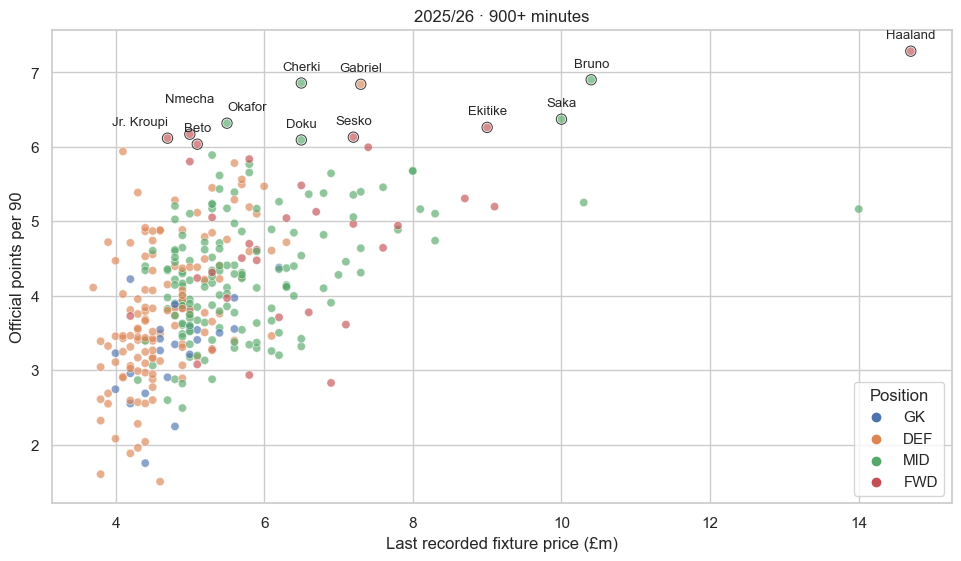

In [25]:
value_leaders = benchmark_rankings.loc[
    benchmark_rankings.ranking.eq("points_per_million")
].groupby("position", sort=False).head(3)
display(value_leaders[[
    "position", "rank", "name", "last_recorded_price_m", "points_per_million",
]].reset_index(drop=True))
fig, ax = plt.subplots(figsize=(9.5, 5.5), layout="constrained")
sns.scatterplot(data=benchmark_cohort, x="last_recorded_price_m", y="official_points_per90",
                hue="position", hue_order=POSITION_ORDER, palette=POSITION_COLORS, alpha=.65, ax=ax)
ax.set(title="2025/26 · 900+ minutes", xlabel="Last recorded fixture price (£m)",
       ylabel="Official points per 90")
ax.legend(loc="lower right", title="Position")
price_labels = benchmark_cohort.loc[benchmark_cohort.official_points_per90.gt(6)]
price_annotations = annotate_points(
    ax, price_labels, "last_recorded_price_m", "official_points_per90",
    aliases=PRICE_LABEL_ALIASES, above=True,
)
assert len(price_annotations) == len(price_labels)
plt.show()

### Positional production and defensive reliability

Attackers are compared on actual returns and expected opportunity. Defensive thresholds use
fixture counts and position-specific definitions, not per-90 threshold crossings. Clean sheets
are recorded FPL player awards; they do not describe whole-team shutouts. Goalkeeper save
volume measures workload as well as contribution. All tables below use the 900-minute cohort.

In [26]:
attacking = benchmark_cohort.loc[benchmark_cohort.position.isin(["MID", "FWD"])]
display(attacking.nlargest(10, "goal_involvements_per90")[[
    "name", "position", "goals", "assists", "goal_involvements_per90",
]].reset_index(drop=True))
display(attacking.nlargest(8, "xgi_per90")[[
    "name", "position", "minutes", "xg_per90", "xa_per90", "xgi_per90",
]].reset_index(drop=True))

,name,position,goals,assists,goal_involvements_per90
0,Erling Haaland,FWD,27,8,1.0667
1,Bruno Borges Fernandes,MID,9,24,0.9690
2,Rayan Cherki,MID,4,13,0.8634
3,João Pedro Junqueira de Jesus,FWD,15,9,0.8126
4,Hugo Ekitiké,FWD,11,4,0.7513
5,Benjamin Sesko,FWD,11,2,0.7178
6,Junior Kroupi,FWD,13,0,0.7035
7,Richarlison de Andrade,FWD,11,4,0.6909
8,Bukayo Saka,MID,7,10,0.6898
9,Jérémy Doku,MID,5,8,0.6599


,name,position,minutes,xg_per90,xa_per90,xgi_per90
0,Erling Haaland,FWD,2953,0.7772,0.0814,0.8586
1,Lukas Nmecha,FWD,1065,0.6127,0.1335,0.7462
2,David Brooks,MID,1188,0.4402,0.2576,0.6977
3,Bruno Borges Fernandes,MID,3065,0.3168,0.3606,0.6774
4,Rayan Cherki,MID,1772,0.2174,0.4505,0.6674
5,Jean-Philippe Mateta,FWD,2210,0.5872,0.0538,0.6410
6,Hugo Ekitiké,FWD,1797,0.5058,0.1227,0.6285
7,Igor Thiago Nascimento Rodrigues,FWD,3282,0.5649,0.0502,0.6151


In [27]:
defensive_leaders = benchmark_cohort.loc[benchmark_cohort.position.isin(["DEF", "MID"])]
defensive_leaders = defensive_leaders.sort_values(
    ["position", "defensive_hit_rate", "minutes"], ascending=[True, False, False],
).groupby("position", sort=False).head(5)
display(defensive_leaders[[
    "name", "position", "minutes", "defensive_hits", "defensive_hit_rate",
]].reset_index(drop=True))
defenders = benchmark_cohort.loc[benchmark_cohort.position.eq("DEF")]
display(defenders.nlargest(5, "clean_sheets")[[
    "name", "minutes", "clean_sheets", "clean_sheet_rate_60plus", "goals", "assists",
]].reset_index(drop=True))

,name,position,minutes,defensive_hits,defensive_hit_rate
0,Marcos Senesi Barón,DEF,3288,26,0.7027
1,Joachim Andersen,DEF,2882,20,0.6061
2,James Tarkowski,DEF,3330,22,0.5946
3,Konstantinos Mavropanos,DEF,2532,18,0.5806
4,Maxence Lacroix,DEF,3085,20,0.5714
5,Elliot Anderson,MID,3332,26,0.6842
6,Ethan Ampadu,MID,3119,19,0.5429
7,James Garner,MID,3413,20,0.5263
8,Rodrigo Bentancur,MID,1880,13,0.5000
9,André Trindade da Costa Neto,MID,2760,16,0.4571


,name,minutes,clean_sheets,clean_sheet_rate_60plus,goals,assists
0,Gabriel dos Santos Magalhães,2750,18,0.6000,3,5
1,William Saliba,2614,15,0.5357,1,0
2,Marc Guéhi,3150,14,0.4000,3,5
3,Nico O'Reilly,2643,14,0.5000,5,4
4,Riccardo Calafiori,1697,13,0.6842,1,2


In [28]:
keepers = benchmark_cohort.loc[benchmark_cohort.position.eq("GK")]
display(keepers.nlargest(5, "official_points")[[
    "name", "minutes", "saves", "saves_per90", "clean_sheets", "penalties_saved",
]].reset_index(drop=True))
consistency = benchmark_cohort.nlargest(10, "official_points")
display(consistency[[
    "name", "position", "median_points", "points_iqr", "six_plus_rate", "attacking_return_rate",
]].reset_index(drop=True))

,name,minutes,saves,saves_per90,clean_sheets,penalties_saved
0,David Raya Martín,3330,60,1.6216,19,0
1,Caoimhín Kelleher,3330,109,2.9459,10,3
2,Robin Roefs,3150,109,3.1143,10,1
3,Jordan Pickford,3420,100,2.6316,11,1
4,Gianluigi Donnarumma,3060,78,2.2941,15,1


,name,position,median_points,points_iqr,six_plus_rate,attacking_return_rate
0,Erling Haaland,FWD,6.0000,9.0000,0.5429,0.6286
1,Bruno Borges Fernandes,MID,5.0000,7.0000,0.4857,0.6571
2,Gabriel dos Santos Magalhães,DEF,6.0000,6.2500,0.6562,0.2500
3,Antoine Semenyo,MID,4.0000,5.0000,0.4324,0.4865
4,Morgan Gibbs-White,MID,3.0000,6.0000,0.3784,0.4324
5,Jarrod Bowen,FWD,4.0000,5.7500,0.3421,0.4474
6,Declan Rice,MID,4.0000,3.0000,0.3056,0.3333
7,Igor Thiago Nascimento Rodrigues,FWD,2.0000,4.0000,0.3158,0.4211
8,Elliot Anderson,MID,4.0000,3.5000,0.2632,0.2105
9,Marc Guéhi,DEF,4.0000,5.0000,0.4571,0.2286


### Expected versus actual returns

Use one fully observed outfield player-season per point, with at least 900 minutes. Show an
intercept-bearing descriptive OLS line and an equality reference. `G − xG` measures the gap
from expected goals; the fit residual measures distance from the fitted sample relationship.
They are different quantities. Totals share playing-time exposure; per-90 checks follow below.

The assist chart uses **FPL assists**, whose definition differs from the standard assists
targeted by xA. Its equality line is a numerical reference, not a calibrated benchmark.
`A − xA` is labelled an FPL assist award gap, not pure assisting skill. These gaps do not prove
persistent ability or guarantee a future reversal. See [FPL's xA definition](https://www.premierleague.com/en/news/2683145/fpl-glossary)
and [the finishing-skill research](https://people.cs.kuleuven.be/~pieter.robberechts/repo/Davis2023_MLSA_xmskill.pdf).

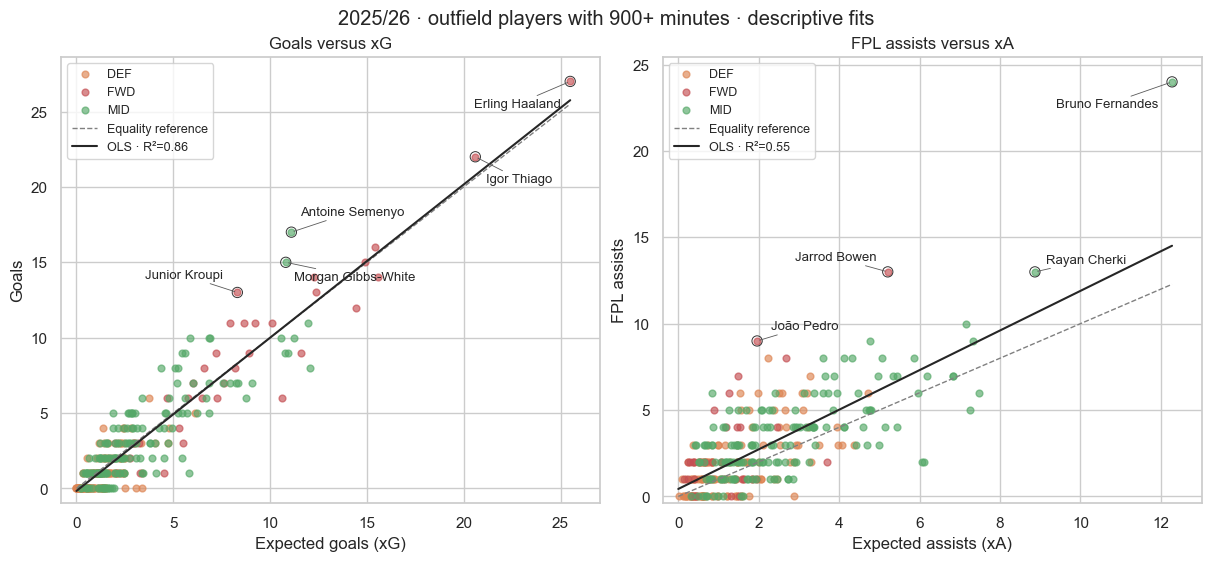

,expected,actual,minimum_minutes,players,intercept,slope,r_squared
0,xg,goals,900,315,-0.1672,1.0165,0.8578
1,xa,assists,900,315,0.4331,1.1465,0.5458


In [29]:
goal_fit = fit_expected_actual(benchmark, "xg", "goals", MIN_HISTORY_MINUTES)
assist_fit = fit_expected_actual(benchmark, "xa", "assists", MIN_HISTORY_MINUTES)
goal_labels = leading_player_labels(goal_fit["players"], "goals", extra_ids=[515, 100])
assist_labels = leading_player_labels(assist_fit["players"], "assists", extra_ids=[249])
label_offsets = {
    430: (-10, 8), 136: (8, -12), 82: (6, 10), 515: (6, -6), 100: (-10, 8),
    449: (-10, -12), 417: (8, 4), 624: (-8, 6), 249: (10, 6),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), layout="constrained")
for ax, fit, expected, actual, title in [
    (axes[0], goal_fit, "xg", "goals", "Goals versus xG"),
    (axes[1], assist_fit, "xa", "assists", "FPL assists versus xA"),
]:
    plot_expected_fit(fit, expected, actual, ax, POSITION_COLORS)
    x_label = "Expected goals (xG)" if expected == "xg" else "Expected assists (xA)"
    y_label = "Goals" if actual == "goals" else "FPL assists"
    ax.set(title=title, xlabel=x_label, ylabel=y_label)
    ax.legend(loc="upper left", fontsize=9)
fig.suptitle("2025/26 · outfield players with 900+ minutes · descriptive fits")
for ax, selected, expected, actual in [
    (axes[0], goal_labels, "xg", "goals"), (axes[1], assist_labels, "xa", "assists"),
]:
    annotate_points(ax, selected, expected, actual, aliases=LABEL_ALIASES, offsets=label_offsets)
assert len(goal_labels) == 5 and len(assist_labels) == 4
plt.show()
display(pd.concat([goal_fit["statistics"], assist_fit["statistics"]], ignore_index=True))

### Largest observed gaps

Show both positive and negative gaps, with minutes and the fitted residual alongside them.
These are descriptive rankings within the selected cohort. Penalties remain included in the
goal totals. FPL assist award gaps also reflect the definition mismatch noted above.

In [30]:
goal_gaps = pd.concat([
    goal_fit["players"].nlargest(3, "G_minus_xG"),
    goal_fit["players"].nsmallest(3, "G_minus_xG"),
])
display(goal_gaps[[
    "name", "minutes", "xg", "goals", "G_minus_xG", "fit_residual",
]].reset_index(drop=True))
assist_gaps = pd.concat([
    assist_fit["players"].nlargest(3, "A_minus_xA"),
    assist_fit["players"].nsmallest(3, "A_minus_xA"),
])
display(assist_gaps[[
    "name", "minutes", "xa", "assists", "A_minus_xA", "fit_residual",
]].reset_index(drop=True))

,name,minutes,xg,goals,G_minus_xG,fit_residual
0,Antoine Semenyo,3200,11.1000,17,5.9000,5.8837
1,Junior Kroupi,1663,8.3100,13,4.6900,4.7199
2,Morgan Gibbs-White,3101,10.8100,15,4.1900,4.1785
3,David Brooks,1188,5.8100,1,-4.8100,-4.7388
4,Francisco Evanilson de Lima Barbosa,2741,10.6400,6,-4.6400,-4.6487
5,Kevin Schade,2744,12.0800,8,-4.0800,-4.1125


,name,minutes,xa,assists,A_minus_xA,fit_residual
0,Bruno Borges Fernandes,3065,12.2800,24,11.7200,9.4879
1,Jarrod Bowen,3406,5.2100,13,7.7900,6.5936
2,João Pedro Junqueira de Jesus,2658,1.9600,9,7.0400,6.3198
3,Yéremy Pino Santos,2074,6.1200,2,-4.1200,-5.4497
4,Mathias Jensen,2239,6.0600,2,-4.0600,-5.3809
5,Gabriel Gudmundsson,2637,2.8900,0,-2.8900,-3.7465


Within this 2025/26 cohort, Semenyo has the largest positive goal gap (+5.90) and Brooks the
largest negative gap (−4.81). Fernandes' FPL assist gap is +11.72, while his fitted-line
residual is +9.49: neither quantity isolates assisting ability because the award definitions
differ. These are findings from the saved dataset and selected cohort, not forecasts.

### Exposure and cohort sensitivity

Refit totals at 450, 900 and 1,350 minutes, and compare with per-90 fits at 900 minutes.
A change in fit is descriptive evidence of sensitivity to exposure or cohort composition.
R-squared here summarizes association in the observed sample, not forecast accuracy.

In [31]:
fit_checks = [
    fit_expected_actual(benchmark, expected, actual, cutoff)["statistics"]
    for cutoff in [450, MIN_HISTORY_MINUTES, 1350]
    for expected, actual in [("xg", "goals"), ("xa", "assists")]
]
fit_checks += [
    fit_expected_actual(benchmark, expected, actual, MIN_HISTORY_MINUTES)["statistics"]
    for expected, actual in [("xg_per90", "goals_per90"), ("xa_per90", "assists_per90")]
]
regression_checks = pd.concat(fit_checks, ignore_index=True)
display(regression_checks)
expected_actual_players = pd.concat([
    goal_fit["players"].assign(comparison="Goals vs xG"),
    assist_fit["players"].assign(comparison="FPL assists vs xA"),
], ignore_index=True)

,expected,actual,minimum_minutes,players,intercept,slope,r_squared
0,xg,goals,450,372,-0.1902,1.0181,0.8599
1,xa,assists,450,372,0.4125,1.1527,0.5691
2,xg,goals,900,315,-0.1672,1.0165,0.8578
3,xa,assists,900,315,0.4331,1.1465,0.5458
4,xg,goals,1350,241,-0.0990,1.0205,0.8674
5,xa,assists,1350,241,0.5374,1.1333,0.5277
6,xg_per90,goals_per90,900,315,-0.0045,0.9697,0.7778
7,xa_per90,assists_per90,900,315,0.0289,1.0531,0.4226


The 900-minute outfield cohort contains 315 players. The goal fit is approximately
`G = −0.17 + 1.02 × xG` (R² 0.858); the assist fit is `FPL A = 0.43 + 1.15 × xA` (R² 0.546).
Per-90 fits have lower R² values of 0.778 and 0.423. Totals share playing-time exposure; the difference in fit is not a skill estimate. The goal slope remains close to one at the checked minute cutoffs;
this is descriptive stability within the saved sample, not out-of-sample validation.

### Validate the historical extension

Confirm that all historical player-season identities remain available, source points reconcile
with the summaries, no current-season rows entered the extension, and every regression
observation has the required playing-time and expected-stat exposure. Save full tables rather
than only the leaderboard previews. No original player records or defensive values are changed.

In [32]:
assert historical_performance.official_points.sum() == historical_matches.P_off.sum()
assert historical_performance.goals.sum() == historical_matches.goals_scored.sum()
assert historical_performance.assists.sum() == historical_matches.assists.sum()
require_keys(historical_performance, ["season", "fpl_player_id", "position"], "performance")
assert expected_actual_players.season.eq(BENCHMARK_SEASON).all()
assert expected_actual_players.minutes.ge(MIN_HISTORY_MINUTES).all()
assert expected_actual_players.position.ne("GK").all()
assert np.isclose(goal_fit["players"].fit_residual.sum(), 0)
assert np.isclose(assist_fit["players"].fit_residual.sum(), 0)
assert historical_matches.equals(working_player_matches.loc[historical_matches.index])

## 2025/26 team performance

Derive historical team results from completed fixture scores, using 2025/26 as the main
benchmark. Earlier team-seasons provide context rather than repeated league tables. Current
season progress remains later work.

Football results-based points (`3 × W + D`) are separate from player FPL points. Administrative
deductions and full official tie-breaking rules are not recorded here. Rank by results-based
points, goal difference and goals for, retaining shared ranks for remaining ties.

In [33]:
from src.team_analysis import (
    TEAM_SEASON_KEY, contribution_concentration, historical_team_results,
    rank_team_results, summarize_team_results, validate_team_results,
)

historical_team_matches = historical_team_results(
    historical_matches, working_fixtures, working_teams, historical_expected_coverage,
)
historical_team_performance = rank_team_results(summarize_team_results(historical_team_matches))
historical_team_validation = validate_team_results(historical_team_matches, working_fixtures)
team_benchmark = historical_team_performance.loc[
    historical_team_performance.season.eq(BENCHMARK_SEASON)
].copy()
display(historical_team_validation.groupby("season").passed.agg(checks="size", passed="sum"))

,checks,passed
season,,
2022_2023,7,7
2023_2024,7,7
2024_2025,7,7
2025_2026,7,7


### Results and goal balance

The full benchmark includes twenty clubs and 38 matches each. Goals for and against come
from fixture scores, including own-goal effects. Do not sum player goals-conceded or clean-sheet
awards into these totals. `P` is played, `Pts` is results-based league points, and `GF/GA/GD`
are goals for, goals against and goal difference.

In [34]:
standing_columns = {
    "team": "Team", "played": "P", "wins": "W", "draws": "D", "losses": "L",
    "points": "Pts", "goals_for": "GF", "goals_against": "GA", "goal_difference": "GD",
}
display(team_benchmark.set_index("results_rank")[list(standing_columns)].rename(
    columns=standing_columns,
).rename_axis("Results rank"))
assert len(team_benchmark) == 20 and team_benchmark.played.eq(38).all()

,Team,P,W,D,L,Pts,GF,GA,GD
Results rank,,,,,,,,,
1,Arsenal,38,26,7,5,85,71,27,44
2,Man City,38,23,9,6,78,77,35,42
3,Man Utd,38,20,11,7,71,69,50,19
4,Aston Villa,38,19,8,11,65,56,49,7
5,Liverpool,38,17,9,12,60,63,53,10
6,Bournemouth,38,13,18,7,57,58,54,4
7,Sunderland,38,14,12,12,54,42,48,-6
8,Brighton,38,14,11,13,53,52,46,6
9,Brentford,38,14,11,13,53,55,52,3


### Expected-stat coverage and historical context

Team xG sums player expectations once per native player-fixture. Team xG against is the
opponent's corresponding team xG; summing player xG-conceded fields would duplicate chances.
Unknown or suspect measurements remain unavailable. Actual-versus-expected gaps use only
matching fixtures, and paired xG difference requires both sides to be observed.

The reference below summarizes sixty earlier team-seasons. Actual results use complete seasons;
expected-stat exposure can be partial in 2022/23 and is reported separately.

In [35]:
display(historical_team_performance.groupby("season").agg(
    clubs=("fpl_team_id", "size"), min_played=("played", "min"), max_played=("played", "max"),
    min_xg_fixtures=("xg_fixtures", "min"), max_xg_fixtures=("xg_fixtures", "max"),
))
team_reference_metrics = ["points_per_match", "goals_for_per_match",
                          "goals_against_per_match", "clean_sheet_rate"]
earlier_teams = historical_team_performance.loc[
    historical_team_performance.season.ne(BENCHMARK_SEASON)
]
historical_team_reference = earlier_teams[team_reference_metrics].quantile([.25, .5, .75]).T
historical_team_reference.columns = ["earlier_q25", "earlier_median", "earlier_q75"]
historical_team_reference["benchmark_median"] = team_benchmark[team_reference_metrics].median()
display(historical_team_reference)

,clubs,min_played,max_played,min_xg_fixtures,max_xg_fixtures
season,,,,,
2022_2023,20,38,38,24,25
2023_2024,20,38,38,38,38
2024_2025,20,38,38,38,38
2025_2026,20,38,38,38,38


,earlier_q25,earlier_median,earlier_q75,benchmark_median
points_per_match,1.0461,1.3684,1.7368,1.3684
goals_for_per_match,1.1447,1.4605,1.7961,1.3289
goals_against_per_match,1.2105,1.5132,1.7237,1.3553
clean_sheet_rate,0.1842,0.2368,0.3158,0.2368


### Attack and defensive context

Compare actual and expected goals per match. Lower values on the vertical axis mean fewer
opposition goals/chances; the lower-right region combines stronger attack with less conceded.
Dashed lines show benchmark means. Small club crests replace dots at their exact data
coordinates. All club emblems load from `logos/`; coverage is checked for every historical
and current season. Points per match remain available in the team tables.

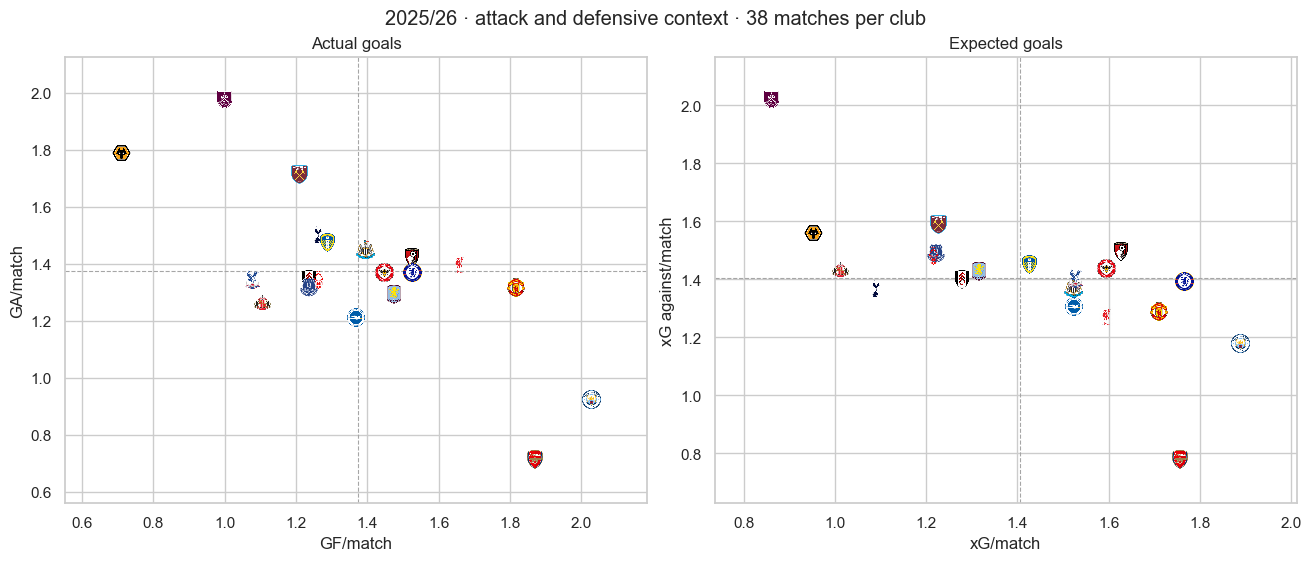

In [36]:
season_logo_files = {
    season: team_logo_paths(frame.rename(columns={"name": "team"}), PROJECT_ROOT / "logos")
    for season, frame in working_teams.groupby("season", sort=True)
}
team_logo_files = season_logo_files[BENCHMARK_SEASON]
team_axes = [
    ("goals_for_per_match", "goals_against_per_match", "Actual goals", "GF/match", "GA/match"),
    ("xg_per_match", "xga_per_match", "Expected goals", "xG/match", "xG against/match"),
]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
for ax, (x, y, title, xlabel, ylabel) in zip(axes, team_axes):
    crests = annotate_team_logos(ax, team_benchmark, x, y, team_logo_files, size_points=13)
    assert len(crests) == len(team_benchmark)
    ax.axvline(team_benchmark[x].mean(), color=".65", linestyle="--", linewidth=.8)
    ax.axhline(team_benchmark[y].mean(), color=".65", linestyle="--", linewidth=.8)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.margins(.12)
fig.suptitle("2025/26 · attack and defensive context · 38 matches per club")
plt.show()

In the saved 2025/26 results, Arsenal have the most results-based points (85) and the fewest
goals conceded (27). Man City score the most goals (77). The expected-stat panel adds chance
context; it does not establish that every difference is persistent team quality.

In [37]:
team_goal_gaps = pd.concat([
    team_benchmark.nlargest(3, "goals_minus_xg"),
    team_benchmark.nsmallest(3, "goals_minus_xg"),
])
display(team_goal_gaps[[
    "team", "goals_for", "xg", "goals_minus_xg", "goals_against", "xga", "conceded_minus_xga",
]].rename(columns={
    "team": "Team", "goals_for": "GF", "xg": "xG", "goals_minus_xg": "GF − xG",
    "goals_against": "GA", "xga": "xGA", "conceded_minus_xga": "GA − xGA",
}).round(2).reset_index(drop=True))
assert team_benchmark.xg_fixtures.eq(38).all() and team_benchmark.xga_fixtures.eq(38).all()

,Team,GF,xG,GF − xG,GA,xGA,GA − xGA
0,Spurs,48,41.4500,6.5500,57,51.8900,5.1100
1,Aston Villa,56,49.9500,6.0500,49,54.2100,-5.2100
2,Burnley,38,32.7100,5.2900,75,76.6800,-1.6800
3,Crystal Palace,41,58.0700,-17.0700,51,53.3000,-2.3000
4,Wolves,27,36.2300,-9.2300,68,59.2000,8.8000
5,Chelsea,58,67.0900,-9.0900,52,52.9000,-0.9000


Across the same 38 benchmark fixtures, Crystal Palace have the largest negative goal gap (41 goals versus 58.07 xG), while Spurs have the largest positive gap (48 versus 41.45). These fixture-goal gaps include own-goal effects and do not establish persistent finishing skill.

### Venue and dependence on individual contributors

Home/away points rates describe the observed season, including timing and squad differences;
they are not an isolated causal home effect. Contribution concentration keeps transferred
players' club stints separate.

The top-three share uses the club's total credited **player goals plus FPL assists** as its
denominator, rather than unique team goals. A goal and its assist are separate credits. The
leading-scorer share instead divides that player's goals by fixture team goals, including
opponent own goals. Neither share measures performance without those players.

In [38]:
historical_team_venues = summarize_team_results(
    historical_team_matches, by=TEAM_SEASON_KEY + ["was_home"],
)
venue_benchmark = historical_team_venues.loc[
    historical_team_venues.season.eq(BENCHMARK_SEASON)
]
venue_comparison = venue_benchmark.pivot(
    index=["fpl_team_id", "team"], columns="was_home", values="points_per_match",
).rename(columns={False: "away_ppg", True: "home_ppg"}).reset_index()
venue_comparison["home_minus_away_ppg"] = venue_comparison.home_ppg - venue_comparison.away_ppg
team_contributions = contribution_concentration(historical_matches, historical_team_performance)
historical_team_concentration = team_contributions["teams"]
historical_player_team_stints = team_contributions["player_stints"]
concentration_benchmark = historical_team_concentration.loc[
    historical_team_concentration.season.eq(BENCHMARK_SEASON)
]

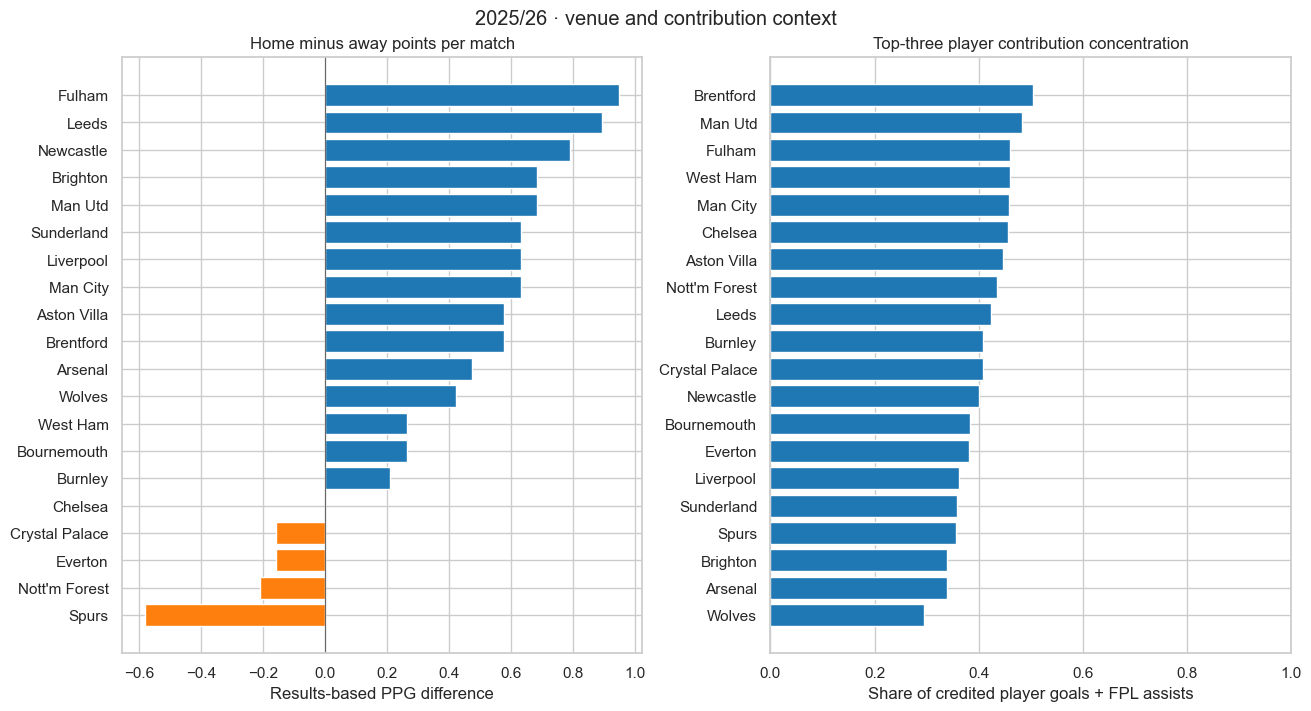

,team,club_involvements,top3_involvement_share,leading_scorer_goal_share
0,Brentford,101,0.5050,0.4000
1,Man Utd,126,0.4840,0.1590
2,Fulham,87,0.4600,0.2130
3,West Ham,87,0.4600,0.1960
4,Man City,142,0.4580,0.3510


In [39]:
venue_plot = venue_comparison.sort_values("home_minus_away_ppg")
concentration_plot = concentration_benchmark.sort_values("top3_involvement_share")
fig, axes = plt.subplots(1, 2, figsize=(13, 7), layout="constrained")
axes[0].barh(venue_plot.team, venue_plot.home_minus_away_ppg,
             color=np.where(venue_plot.home_minus_away_ppg.ge(0), "tab:blue", "tab:orange"))
axes[0].axvline(0, color=".4", linewidth=.8)
axes[0].set(title="Home minus away points per match", xlabel="Results-based PPG difference")
axes[1].barh(concentration_plot.team, concentration_plot.top3_involvement_share, color="tab:blue")
axes[1].set(title="Top-three player contribution concentration",
            xlabel="Share of credited player goals + FPL assists", xlim=(0, 1))
fig.suptitle("2025/26 · venue and contribution context")
plt.show()
display(concentration_benchmark.nlargest(5, "top3_involvement_share")[[
    "team", "club_involvements", "top3_involvement_share", "leading_scorer_goal_share",
]].round(3).reset_index(drop=True))

Fulham have the largest positive home-minus-away points-rate difference (0.95 per match); Spurs have the largest negative difference (−0.58). Brentford have the highest top-three share of credited player goals plus FPL assists (50.5%). These are descriptive season-level patterns, not estimates of what would happen if a player or venue changed.

### Validate team results and preserve the source

Check source-score totals, W/D/L, results-based point allocation, own-goal reconciliation and
native keys. Expected-stat coverage remains explicit; current-season observations do not enter
this historical report. The full team tables, venue splits and player-club stints are exported.

In [40]:
require_keys(historical_team_matches, TEAM_FIXTURE_KEY, "historical team matches")
require_keys(historical_team_performance, ["season", "fpl_team_id"], "team performance")
assert len(historical_team_matches) == 3040 and len(historical_team_performance) == 80
assert not historical_team_matches.season.eq(CURRENT_SEASON).any()
assert historical_team_validation.passed.all()
assert venue_benchmark.played.eq(19).all()
assert concentration_benchmark.top3_involvement_share.between(0, 1).all()
assert historical_matches.equals(working_player_matches.loc[historical_matches.index])

## Patterns across historical seasons

Compare mechanisms rather than repeating every leaderboard. The first table counts how often
point-source patterns recur across the four seasons, using positive-minute appearances in
both the component numerator and denominator. Official defensive awards enter only in 2025/26;
reconstructed historical activity is not retroactively added to official points. The detailed
16-group component table is exported. These averages describe awarded points, not player ability.

In [41]:
from src.analysis_synthesis import seasonal_point_patterns, seasonal_team_patterns

historical_patterns = seasonal_point_patterns(historical_components)
historical_season_components = historical_patterns["detail"]
historical_player_recurrence = historical_patterns["recurrence"]
display(historical_player_recurrence.set_index("position").reindex(POSITION_ORDER))

,seasons,appearance_largest,largest_other_source,other_source_repeats,min_points_per_appearance,max_points_per_appearance
position,,,,,,
GK,4,4,Clean sheets,4,3.1946,3.6104
DEF,4,4,Clean sheets,4,2.4197,3.0476
MID,4,4,Attacking,4,2.6936,2.9128
FWD,4,4,Attacking,4,2.9454,3.2075


In [42]:
historical_team_patterns = seasonal_team_patterns(
    historical_team_matches, historical_team_performance,
)
display(historical_team_patterns.rename(columns={
    "scored_rho": "PPG ~ GF/m", "conceded_rho": "PPG ~ GA/m",
    "gd_rho": "PPG ~ GD/m", "xgd_rho": "Paired PPG ~ xGD/m",
}))

,season,clubs,all_team_fixtures,paired_team_fixtures,PPG ~ GF/m,PPG ~ GA/m,PPG ~ GD/m,Paired PPG ~ xGD/m
0,2022_2023,20,760,488,0.8152,-0.8809,0.9466,0.7965
1,2023_2024,20,760,760,0.9110,-0.7828,0.9276,0.7977
2,2024_2025,20,760,760,0.8543,-0.8613,0.9548,0.9100
3,2025_2026,20,760,760,0.8293,-0.7541,0.9134,0.7595


Appearance points lead in every season/position group. Clean sheets remain the largest other
source for keepers/defenders, while attacking returns do so for midfielders/forwards. In 2025/26,
defensive awards add a new official source rather than evidence of a historical ability change.

For teams, higher scoring and lower conceding rates accompany higher points in every season.
Goal-difference correlations range from 0.913 to 0.955. The xGD correlations range from 0.760 to
0.910, with each club's points recomputed on its paired xG/xGA fixtures. Early 2022/23 gaps leave
488 covered team-fixtures out of 760; the other seasons have 760 each. The coefficients use
20 clubs per season, reflect shared match outcomes and scoring rules, and do not establish
causal importance or out-of-sample prediction.

## Current player progress

Analyse the saved 2026/27 season through GW10 separately from completed-season rankings.
All 672 captured players remain in the performance table. Comparison rankings use at least
450 minutes and players selectable in the captured FPL snapshot; this flag does not guarantee
fitness or a start. Availability, price and ownership describe collection time only.

Recent progress uses the current club's last five completed fixtures, retaining observed
zero-minute records. Missing records remain unknown, including pre-arrival opportunities.
Season totals still include earlier club stints; their recent current-club window is different.

In [43]:
from src.current_player_analysis import current_player_progress

MIN_CURRENT_MINUTES = 450
current_matches = working_player_matches.loc[working_player_matches.season.eq(CURRENT_SEASON)]
current_expected_coverage = expected_coverage(current_matches)
current_progress = current_player_progress(
    current_matches, tables["current_players"], working_teams,
    working_fixtures, current_expected_coverage, window_size=5,
)
current_performance = current_progress["players"]
recent_current_records = current_progress["recent_records"]
current_club_windows = current_progress["windows"]
CURRENT_LABELS = current_performance.set_index("fpl_player_id").display_name.to_dict()
display(current_progress["validation"])
display(tables["current_snapshot_metadata"][["season", "retrieved_at_utc", "last_checked_GW"]])

,metric,players,disagreements
0,official_points,672,0
1,minutes,672,0
2,goals,672,0
3,assists,672,0
4,starts,672,0


,season,retrieved_at_utc,last_checked_GW
0,2026_2027,2026-11-10 21:06:23.051534+00:00,10


### Current cohort and official production

Retain non-selectable players in observed performance. Use the selectable comparison cohort
for the displayed rankings, with source status alongside production. Injury/doubt flags are
not discarded. Unknown next-round playing chances are not replaced with 100%.

In [44]:
current_selectable = current_performance.loc[
    current_performance.can_select & ~current_performance.removed
].copy()
current_comparison = current_selectable.loc[current_selectable.minutes.ge(MIN_CURRENT_MINUTES)]
current_cohort_review = current_performance.groupby("position").agg(
    players=("fpl_player_id", "size"), selectable=("can_select", "sum"),
    with_minutes=("minutes", lambda values: values.gt(0).sum()),
    at_least_450=("minutes", lambda values: values.ge(MIN_CURRENT_MINUTES).sum()),
)
display(current_cohort_review.reindex(POSITION_ORDER))
current_rank_parts = []
current_metrics = ["official_points", "official_points_per90",
                   "snapshot_points_per_million", "xgi_per90"]
for metric in current_metrics:
    pool = current_selectable
    if metric == "xgi_per90":
        pool = pool.loc[pool.position.ne("GK")]
    current_rank_parts.append(rank_players(pool, metric, MIN_CURRENT_MINUTES))
current_rankings = pd.concat(current_rank_parts, ignore_index=True)
current_point_leaders = current_rankings.loc[current_rankings.ranking.eq("official_points")]
display(current_point_leaders.groupby("position", sort=False).head(3)[[
    "position", "rank", "display_name", "official_points", "minutes", "status",
]].reset_index(drop=True))

,players,selectable,with_minutes,at_least_450
position,,,,
GK,75,62,25,21
DEF,219,186,160,81
MID,299,257,221,86
FWD,79,61,53,20


,position,rank,display_name,official_points,minutes,status
0,DEF,1,De Cuyper,75,822,a
1,DEF,2,Vuskovic,70,887,a
2,DEF,3,Gabriel,66,900,a
3,FWD,1,Haaland,70,889,a
4,FWD,2,Evanilson,61,837,a
5,FWD,2,Isak,61,747,a
6,GK,1,Raya,60,900,a
7,GK,2,Verbruggen,57,900,a
8,GK,3,Trafford,54,900,a
9,MID,1,Groß,70,880,a


In the captured data, De Cuyper leads with 75 official points; Groß, Vuskovic and Haaland have 70 each. These are observed totals, and current availability is a separate snapshot attribute. The 450-minute cohort contains 208 players, all selectable at capture time.

### Dated price context

Use `now_cost` at the saved snapshot, not a historical end-of-season price or a verified
pre-deadline purchase price. Value rankings are retrospective. The plot labels every
450-minute comparison player with official points per 90 strictly above seven. Short names
sit above the points without connecting lines or filled backgrounds. The chart does not
recommend transfers.

,position,display_name,snapshot_price_m,snapshot_points_per_million,status
0,DEF,De Cuyper,5.5000,13.6364,a
1,DEF,Vuskovic,5.3000,13.2075,a
2,DEF,Bogle,4.8000,12.0833,a
3,FWD,Barry,5.7000,9.6491,a
4,FWD,Evanilson,6.5000,9.3846,a
5,FWD,Kostoulas,5.8000,8.1034,a
6,GK,Verbruggen,4.6000,12.3913,a
7,GK,Trafford,5.0000,10.8000,a
8,GK,Tzolakis,4.7000,10.4255,a
9,MID,Groß,6.3000,11.1111,a


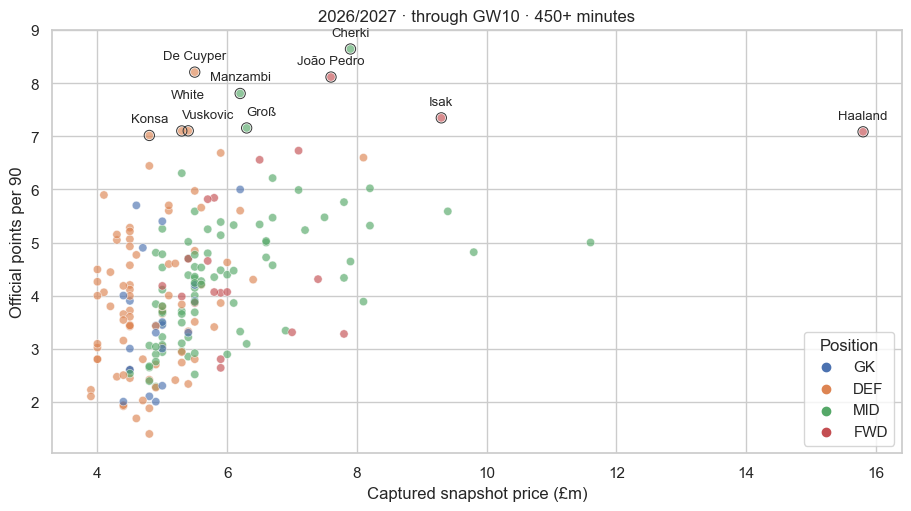

In [45]:
current_value_leaders = current_rankings.loc[
    current_rankings.ranking.eq("snapshot_points_per_million")
].groupby("position", sort=False).head(3)
display(current_value_leaders[[
    "position", "display_name", "snapshot_price_m", "snapshot_points_per_million", "status",
]].reset_index(drop=True))
progress_spotlight = leading_player_labels(current_comparison, "official_points")
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
sns.scatterplot(data=current_comparison, x="snapshot_price_m", y="official_points_per90",
                hue="position", hue_order=POSITION_ORDER, palette=POSITION_COLORS, alpha=.65, ax=ax)
ax.set(title=f"{CURRENT_SEASON.replace('_', '/')} · through GW{LAST_GW} · 450+ minutes",
       xlabel="Captured snapshot price (£m)", ylabel="Official points per 90")
ax.legend(loc="lower right", title="Position")
current_price_labels = current_comparison.loc[current_comparison.official_points_per90.gt(7)]
current_annotations = annotate_points(
    ax, current_price_labels, "snapshot_price_m", "official_points_per90",
    aliases=CURRENT_LABELS, above=True,
)
assert len(current_annotations) == len(current_price_labels)
plt.show()

### Recent opportunity and missing records

The window comes from each current club's calendar, not the player's last five appearances.
A transfer does not turn old-club records into current-club appearances. Only observed rows
contribute to rates; missing opportunities are reported explicitly and are not filled with zero.
A recent rate and its season-to-date counterpart overlap, so their difference is descriptive.

In [46]:
display(current_performance.groupby("recent_records").size().rename("players").to_frame())
missing_recent = current_performance.loc[current_performance.recent_missing_records.gt(0)]
display(missing_recent[[
    "display_name", "current_team", "recent_records", "recent_missing_records", "status",
]].reset_index(drop=True))
opportunity_examples = current_comparison.loc[
    current_comparison.recent_records.eq(current_comparison.club_window_size)
    & current_comparison.recent_minutes.ge(360)
].sort_values(["recent_minutes", "official_points"], ascending=False)
display(opportunity_examples[[
    "display_name", "current_team", "recent_records", "recent_minutes", "recent_starts", "status",
]].head(8).reset_index(drop=True))

,players
recent_records,
1,2
2,1
3,1
4,1
5,667


,display_name,current_team,recent_records,recent_missing_records,status
0,Cissé,Aston Villa,1,4,a
1,Sharman-Lowe,Chelsea,3,2,a
2,Subuloye,Chelsea,2,3,a
3,Gunter,Spurs,1,4,a
4,Tutierov,Sunderland,4,1,a


,display_name,current_team,recent_records,recent_minutes,recent_starts,status
0,Vuskovic,Brighton,5,450,5,a
1,Gabriel,Arsenal,5,450,5,a
2,Raya,Arsenal,5,450,5,a
3,Konsa,Arsenal,5,450,5,a
4,Verbruggen,Brighton,5,450,5,a
5,Van Hecke,Spurs,5,450,5,a
6,Tarkowski,Everton,5,450,5,a
7,Muharemović,Leeds,5,450,5,a


There are 667 complete five-record current-club windows and five incomplete windows. An absent record does not tell us whether the player was eligible or available for that fixture, so it remains a coverage gap rather than a manufactured non-appearance.

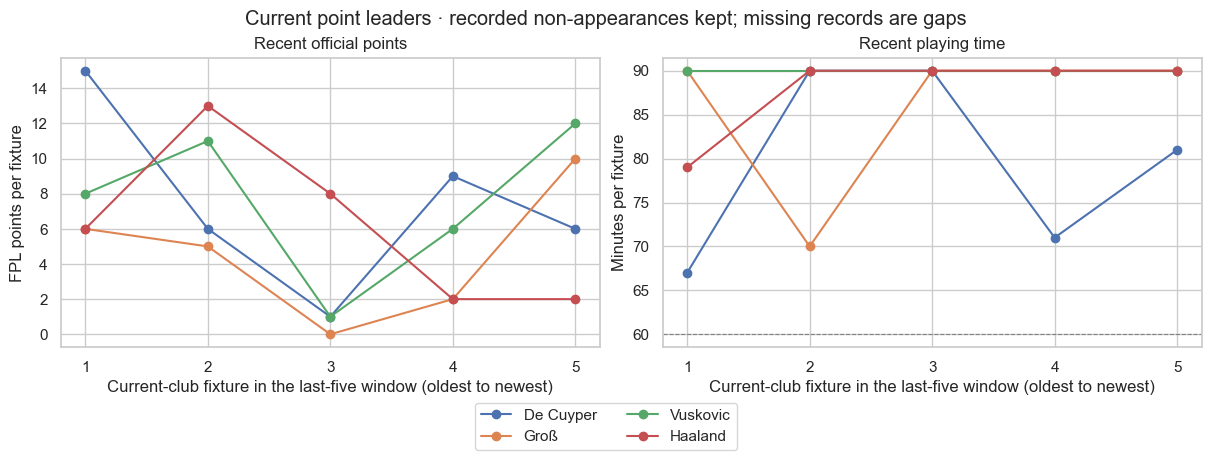

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for color, player in zip(sns.color_palette("deep", len(progress_spotlight)),
                         progress_spotlight.itertuples(index=False)):
    observed = recent_current_records.loc[
        recent_current_records.fpl_player_id.eq(player.fpl_player_id)
    ].set_index("club_fixture_order").reindex(range(1, 6))
    axes[0].plot(observed.index, observed.P_off.astype(float), marker="o", color=color,
                 label=player.display_name)
    axes[1].plot(observed.index, observed.minutes.astype(float), marker="o", color=color)
axes[0].set(title="Recent official points", ylabel="FPL points per fixture")
axes[1].set(title="Recent playing time", ylabel="Minutes per fixture")
axes[1].axhline(60, color=".5", linestyle="--", linewidth=.8)
for ax in axes:
    ax.set(xlabel="Current-club fixture in the last-five window (oldest to newest)",
           xticks=range(1, 6))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2)
fig.suptitle("Current point leaders · recorded non-appearances kept; missing records are gaps")
plt.show()

### Attacking opportunity, defensive reliability and goalkeeping

Show expected opportunity separately from delivered returns. Current defensive counts are
supplied FPL measurements; a high defensive count or save rate also reflects workload.
The following previews use the selectable 450-minute cohort. Full profiles retain all players.

In [48]:
current_attacking = current_comparison.loc[current_comparison.position.ne("GK")]
display(current_attacking.nlargest(8, "xgi_per90")[[
    "display_name", "position", "minutes", "xg_per90", "xa_per90", "xgi_per90",
]].reset_index(drop=True))
current_defensive = current_comparison.loc[current_comparison.position.isin(["DEF", "MID"])]
display(current_defensive.nlargest(8, "defensive_hit_rate")[[
    "display_name", "position", "defensive_hits", "defensive_hit_rate", "minutes", "status",
]].reset_index(drop=True))
current_keepers = current_comparison.loc[current_comparison.position.eq("GK")]
display(current_keepers.nlargest(5, "official_points")[[
    "display_name", "official_points", "saves", "saves_per90", "clean_sheets", "status",
]].reset_index(drop=True))

,display_name,position,minutes,xg_per90,xa_per90,xgi_per90
0,Barry,FWD,851,0.7710,0.0508,0.8217
1,Haaland,FWD,889,0.7147,0.0881,0.8028
2,Saka,MID,596,0.5482,0.1812,0.7294
3,B.Fernandes,MID,810,0.4378,0.2411,0.6789
4,Brobbey,FWD,619,0.6121,0.0189,0.6310
5,Isak,FWD,747,0.5880,0.0337,0.6217
6,Tavernier,MID,840,0.4511,0.1554,0.6064
7,Cherki,MID,562,0.3075,0.2979,0.6053


,display_name,position,defensive_hits,defensive_hit_rate,minutes,status
0,Mainoo,MID,6,0.7500,566,a
1,Mendy,DEF,5,0.7143,519,a
2,Botman,DEF,5,0.7143,630,a
3,Silva,DEF,7,0.7000,900,a
4,Richards,DEF,7,0.7000,900,a
5,Muharemović,DEF,7,0.7000,900,a
6,Murillo,DEF,7,0.7000,899,a
7,Pinnock,DEF,6,0.6667,732,a


,display_name,official_points,saves,saves_per90,clean_sheets,status
0,Raya,60,20,2.0000,7,a
1,Verbruggen,57,26,2.6000,7,a
2,Trafford,54,37,3.7000,4,a
3,Tzolakis,49,41,4.1000,3,a
4,A.Becker,42,25,2.5000,4,a


### Current expected-versus-actual returns

Use fully observed, selectable outfield players with at least 450 minutes. The same descriptive
rules apply as in the historical plots: the goal identity gap and fitted-line residual differ;
FPL assists minus xA is an award-definition gap. Ten gameweeks provide limited exposure and
these fits do not establish persistent skill, future reversal or calibrated scoring probabilities.

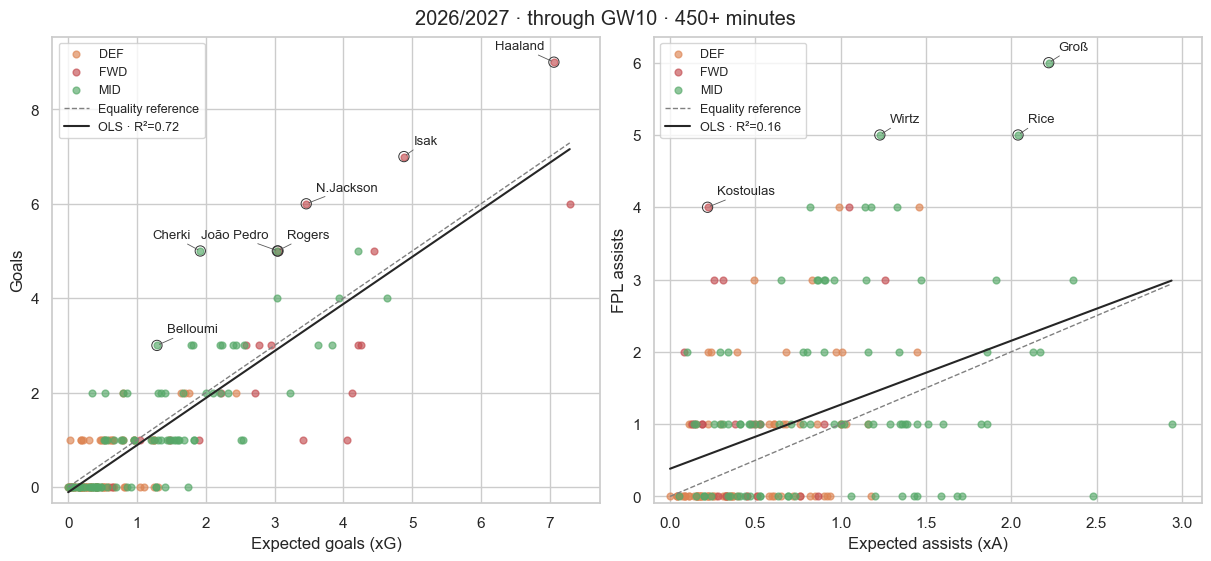

In [49]:
current_goal_fit = fit_expected_actual(current_selectable, "xg", "goals", MIN_CURRENT_MINUTES)
current_assist_fit = fit_expected_actual(current_selectable, "xa", "assists", MIN_CURRENT_MINUTES)
current_goal_labels = leading_player_labels(
    current_goal_fit["players"], "goals", extra_ids=(399, 40, 165, 286),
)
current_goal_labels = current_goal_labels.loc[current_goal_labels.fpl_player_id.ne(249)]
current_assist_labels = leading_player_labels(
    current_assist_fit["players"], "assists", extra_ids=(138,),
)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), layout="constrained")
for ax, fit, expected, actual, selected in [
    (axes[0], current_goal_fit, "xg", "goals", current_goal_labels),
    (axes[1], current_assist_fit, "xa", "assists", current_assist_labels),
]:
    plot_expected_fit(fit, expected, actual, ax, POSITION_COLORS)
    ax.set(xlabel="Expected goals (xG)" if expected == "xg" else "Expected assists (xA)",
           ylabel="Goals" if actual == "goals" else "FPL assists")
    ax.legend(loc="upper left", fontsize=9)
fig.suptitle(f"{CURRENT_SEASON.replace('_', '/')} · through GW{LAST_GW} · 450+ minutes")
for ax, selected, expected, actual in [
    (axes[0], current_goal_labels, "xg", "goals"),
    (axes[1], current_assist_labels, "xa", "assists"),
]:
    annotate_points(ax, selected, expected, actual, aliases=CURRENT_LABELS)
plt.show()

In [50]:
current_goal_gaps = pd.concat([
    current_goal_fit["players"].nlargest(3, "G_minus_xG"),
    current_goal_fit["players"].nsmallest(3, "G_minus_xG"),
])
display(current_goal_gaps[[
    "display_name", "minutes", "goals", "xg", "G_minus_xG", "fit_residual",
]].reset_index(drop=True))
current_assist_gaps = pd.concat([
    current_assist_fit["players"].nlargest(3, "A_minus_xA"),
    current_assist_fit["players"].nsmallest(3, "A_minus_xA"),
])
display(current_assist_gaps[[
    "display_name", "minutes", "assists", "xa", "A_minus_xA", "fit_residual",
]].reset_index(drop=True))
current_expected_actual = pd.concat([
    current_goal_fit["players"].assign(comparison="Goals vs xG"),
    current_assist_fit["players"].assign(comparison="FPL assists vs xA"),
], ignore_index=True)

,display_name,minutes,goals,xg,G_minus_xG,fit_residual
0,Cherki,562,5,1.9200,3.0800,3.1955
1,N.Jackson,722,6,3.4600,2.5400,2.6602
2,Isak,747,7,4.8800,2.1200,2.2446
3,Gonzalo,819,1,4.0500,-3.0500,-2.9280
4,Wissa,707,1,3.4100,-2.4100,-2.2899
5,Thiago,824,2,4.1200,-2.1200,-1.9978


,display_name,minutes,assists,xa,A_minus_xA,fit_residual
0,Groß,880,6,2.2200,3.7800,3.6517
1,Kostoulas,724,4,0.2200,3.7800,3.4222
2,Wirtz,791,5,1.2300,3.7700,3.5281
3,Ødegaard,823,0,2.4800,-2.4800,-2.5785
4,Iwobi,821,1,2.9400,-1.9400,-1.9857
5,Bobb,729,0,1.7100,-1.7100,-1.8968


In [51]:
current_fit_checks = [
    fit_expected_actual(current_selectable, expected, actual, cutoff)["statistics"]
    for cutoff in [270, MIN_CURRENT_MINUTES, 630]
    for expected, actual in [("xg", "goals"), ("xa", "assists")]
]
current_fit_checks += [
    fit_expected_actual(current_selectable, expected, actual, MIN_CURRENT_MINUTES)["statistics"]
    for expected, actual in [("xg_per90", "goals_per90"), ("xa_per90", "assists_per90")]
]
current_regression_checks = pd.concat(current_fit_checks, ignore_index=True)
display(current_regression_checks)

,expected,actual,minimum_minutes,players,intercept,slope,r_squared
0,xg,goals,270,263,-0.0734,0.9705,0.6963
1,xa,assists,270,263,0.2737,0.9342,0.1893
2,xg,goals,450,187,-0.1096,0.9969,0.7178
3,xa,assists,450,187,0.3831,0.8852,0.1581
4,xg,goals,630,136,-0.1428,1.0068,0.7465
5,xa,assists,630,136,0.2802,0.9319,0.1724
6,xg_per90,goals_per90,450,187,-0.0146,1.0069,0.6737
7,xa_per90,assists_per90,450,187,0.0462,0.9601,0.1649


At 450 minutes, the 187-player outfield goal fit is approximately G = −0.11 + 1.00 × xG (R² 0.718), while the FPL-assist fit is A = 0.38 + 0.89 × xA (R² 0.158). The assist relationship is weak in this short window and uses different award definitions; neither fit is forecast validation. Cherki has the largest positive goal gap (+3.08) in this cohort, while Gonzalo has the largest negative gap (−3.05).

### Comparable early-season reference

Use 2025/26 through the same gameweek as a contextual distribution, with 450 minutes required
in both periods. Keep all observed comparison players, including historical departures; no
cross-season player identity link is inferred. Counts show whether gameweek windows have equal
fixture exposure. Rates are comparable units, but short-window variation remains substantial.

In [52]:
historical_window_matches = historical_matches.loc[
    historical_matches.season.eq(BENCHMARK_SEASON) & historical_matches.GW.le(LAST_GW)
]
historical_window_profiles = performance_profiles(
    historical_window_matches, historical_expected_coverage,
)
comparison_fields = ["season", "fpl_player_id", "position", "name", "minutes",
                     "official_points_per90", "xgi_per90"]
current_window_comparison = pd.concat([
    historical_window_profiles.loc[historical_window_profiles.minutes.ge(MIN_CURRENT_MINUTES),
                                   comparison_fields],
    current_performance.loc[current_performance.minutes.ge(MIN_CURRENT_MINUTES), comparison_fields],
], ignore_index=True)
display(pd.DataFrame([
    {"season": frame.season.iloc[0], "fixtures": frame.fpl_fixture_id.nunique(),
     "player_records": len(frame)}
    for frame in [historical_window_matches, current_matches]
]))

,season,fixtures,player_records
0,2025_2026,100,7311
1,2026_2027,100,6562


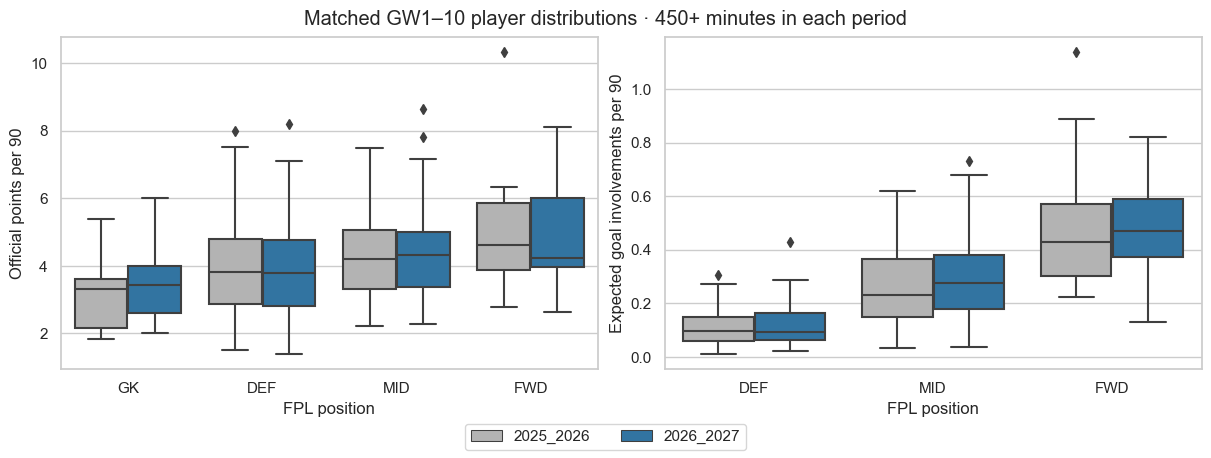

In [53]:
periods = [BENCHMARK_SEASON, CURRENT_SEASON]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, metric, order, ylabel in [
    (axes[0], "official_points_per90", POSITION_ORDER, "Official points per 90"),
    (axes[1], "xgi_per90", POSITION_ORDER[1:], "Expected goal involvements per 90"),
]:
    frame = current_window_comparison.loc[current_window_comparison.position.isin(order)]
    sns.boxplot(data=frame, x="position", y=metric, hue="season", order=order,
                hue_order=periods, palette=[".7", "tab:blue"], ax=ax)
    ax.set(xlabel="FPL position", ylabel=ylabel)
handles, labels = axes[0].get_legend_handles_labels()
for ax in axes:
    ax.get_legend().remove()
fig.legend(handles, labels, loc="outside lower center", ncol=2)
fig.suptitle(f"Matched GW1–{LAST_GW} player distributions · 450+ minutes in each period")
plt.show()

### Validate current progress

Reconcile points, minutes, goals, assists and corrected starts with the captured cumulative
snapshot for every player. Preserve unknown availability chances and adjusted-point values.
Verify that recent records stay within the current club's completed-fixture window and that
all original current player-fixture rows remain unchanged. No predictive model is fitted.

In [54]:
require_keys(current_performance, ["season", "fpl_player_id"], "current player progress")
require_keys(recent_current_records, MATCH_KEY, "recent current-club records")
assert len(current_performance) == len(tables["current_players"])
assert current_progress["validation"].disagreements.eq(0).all()
assert current_performance.official_points.sum() == current_matches.P_off.sum()
assert current_performance.adjusted_points.isna().all()
assert current_performance.chance_of_playing_next_round.isna().sum() == (
    tables["current_players"].chance_of_playing_next_round.isna().sum()
)
assert recent_current_records.fpl_team_id.eq(recent_current_records.snapshot_fpl_team_id).all()
assert current_performance.recent_records.le(current_performance.club_window_size).all()
assert current_matches.equals(working_player_matches.loc[current_matches.index])
assert current_club_windows.kickoff_time.le(snapshot_metadata.retrieved_at_utc).all()

## Current team and opponent context

Use completed 2026/27 fixtures from the saved snapshot, separately from historical standings.
Scores define results-based points (3W+D); administrative deductions are not supplied. Sum
player xG once per team-fixture and obtain xGA from the opposition. Unknown expectations stay
unknown, and actual/expected gaps use matching fixtures. The table reports all twenty clubs.

In [55]:
from src.current_team_analysis import current_team_progress, player_team_context

current_teams = current_team_progress(
    current_matches, working_fixtures, working_teams, current_expected_coverage,
)
current_team_matches = current_teams["matches"]
current_team_report = current_teams["profiles"]
current_opponent_context = current_teams["context"]
display(current_team_report[[
    "results_rank", "team", "played", "wins", "draws", "losses", "points",
    "goals_for", "goals_against", "xg", "xga", "recent_points_per_match",
]].rename(columns={
    "results_rank": "Rank", "team": "Club", "played": "P", "wins": "W", "draws": "D",
    "losses": "L", "points": "Pts", "goals_for": "GF", "goals_against": "GA",
    "xg": "xG", "xga": "xGA", "recent_points_per_match": "Latest-five PPG",
}))
assert len(current_team_matches) == 2 * current_matches.fpl_fixture_id.nunique()
assert current_teams["validation"].passed.all()
assert current_team_report.played.eq(10).all()
assert current_team_report.recent_played.eq(5).all()
assert current_team_report.earlier_played.eq(5).all()

,Rank,Club,P,W,D,L,Pts,GF,GA,xG,xGA,Latest-five PPG
0,1,Arsenal,10,9,0,1,27,15,5,16.1600,7.6300,3.0000
1,2,Brighton,10,7,1,2,22,26,7,19.7000,13.9000,2.4000
2,3,Man City,10,7,0,3,21,21,13,20.0900,12.8100,1.2000
3,4,Liverpool,10,5,3,2,18,14,10,15.8700,13.1900,1.8000
4,5,Chelsea,10,5,1,4,16,19,16,14.1000,15.3600,1.8000
5,6,Everton,10,4,4,2,16,12,10,14.0200,14.2300,1.4000
6,7,Bournemouth,10,4,3,3,15,16,14,18.0800,11.2900,2.4000
7,8,Brentford,10,3,5,2,14,16,11,14.9100,14.9000,1.0000
8,9,Leeds,10,3,5,2,14,10,8,13.4100,12.5700,1.0000
9,10,Aston Villa,10,3,4,3,13,14,17,13.8300,18.7300,1.8000


### Recent results against an earlier window

Compare each club's latest five completed fixtures with its earlier five, rather than comparing
an overlapping recent window with the full season. Bournemouth improve by 1.8 points per match,
Spurs by 1.6 and Fulham by 1.2; City fall by 1.8. Arsenal win all five recent fixtures. These
changes describe realized form and may reflect finishing, schedule or random variation. Home/away mix also differs; current venue summaries are retained in the export.

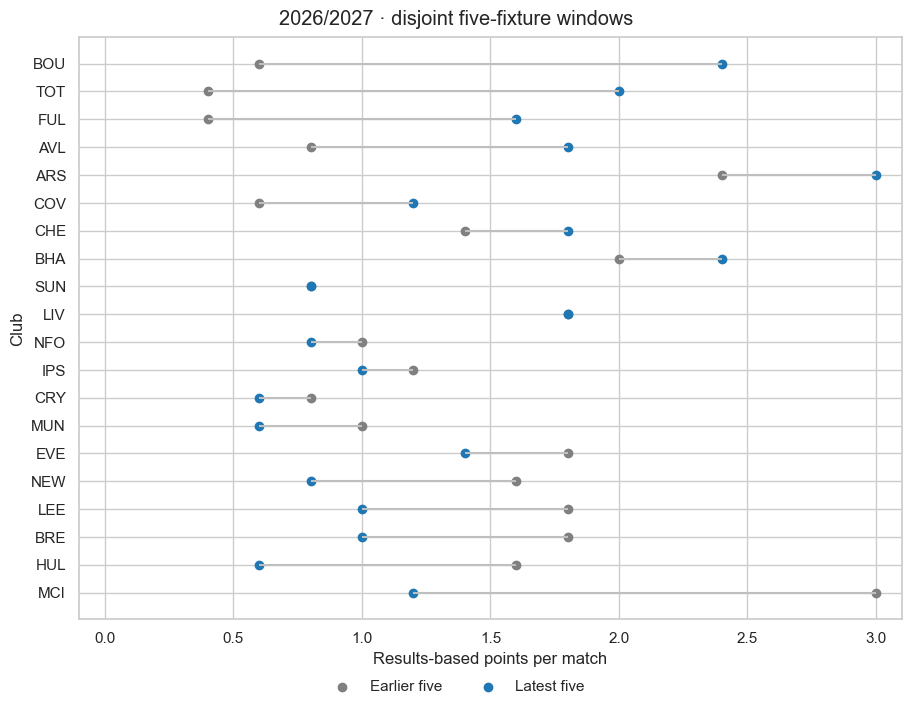

In [56]:
form_comparison = current_team_report.sort_values("recent_minus_earlier_ppg")
y = np.arange(len(form_comparison))
fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
ax.hlines(y, form_comparison.earlier_points_per_match,
          form_comparison.recent_points_per_match, color=".75", linewidth=1.5)
ax.scatter(form_comparison.earlier_points_per_match, y, color=".5", label="Earlier five")
ax.scatter(form_comparison.recent_points_per_match, y, color="tab:blue", label="Latest five")
ax.set_yticks(y, labels=form_comparison.short_name)
ax.set(xlim=(-.1, 3.1), xlabel="Results-based points per match", ylabel="Club")
fig.suptitle(f"{CURRENT_SEASON.replace('_', '/')} · disjoint five-fixture windows")
fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

### Connect player returns with their club and opponents

Retain every snapshot player in the exported context table. The preview shows two recent
point leaders per position among selectable players with five observed current-club records
and at least 225 recent minutes. Team xG/xGA rates use those five club fixtures. Opponent rates
are minute-weighted across the player's appearances, using only the opponents' earlier
completed fixtures in this season and at least three measured prior matches. Higher faced
xGA means the opponents had conceded more expected goals; higher faced xG means they had
created more. The associated minute columns retain coverage. These are contextual comparisons,
not an opponent-adjusted ability score or a forecast. Earlier-club production after transfers
is not attributed to a player's current club.

In [57]:
current_player_team_context = player_team_context(
    current_performance, recent_current_records, current_teams,
)
context_cohort = current_player_team_context.loc[
    current_player_team_context.can_select & ~current_player_team_context.removed
    & current_player_team_context.recent_missing_records.eq(0)
    & current_player_team_context.recent_minutes.ge(225)
]
context_leaders = pd.concat([
    context_cohort.loc[context_cohort.position.eq(position)].nlargest(2, "recent_official_points")
    for position in POSITION_ORDER
])
context_columns = {
    "position": "Pos", "display_name": "Player", "current_team": "Club",
    "recent_minutes": "Recent min", "recent_official_points_per90": "Recent pts/90",
    "team_recent_xg_per_match": "Club xG/m", "team_recent_xga_per_match": "Club xGA/m",
    "faced_xg_per_match": "Opp prior xG/m", "faced_xga_per_match": "Opp prior xGA/m",
}
display(context_leaders[list(context_columns)].rename(columns=context_columns))
assert len(current_player_team_context) == len(current_performance)
assert context_leaders.opponent_prior_xga_per_match_minutes.eq(context_leaders.recent_minutes).all()
assert context_leaders.opponent_prior_xg_per_match_minutes.eq(context_leaders.recent_minutes).all()

,Pos,Player,Club,Recent min,Recent pts/90,Club xG/m,Club xGA/m,Opp prior xG/m,Opp prior xGA/m
124,GK,Verbruggen,Brighton,450,6.8000,1.6300,0.9860,1.7388,1.5638
0,GK,Raya,Arsenal,450,6.0000,1.5300,0.7140,1.4521,1.3185
26,DEF,Konsa,Arsenal,450,9.0000,1.5300,0.7140,1.4521,1.3185
3,DEF,Gabriel,Arsenal,450,8.2000,1.5300,0.7140,1.4521,1.3185
142,MID,Ayari,Brighton,408,6.8382,1.6300,0.9860,1.7547,1.5679
12,MID,Rice,Arsenal,411,6.5693,1.5300,0.7140,1.4840,1.3057
54,FWD,N.Jackson,Aston Villa,436,9.0826,1.8540,1.8980,1.6800,1.5072
88,FWD,Evanilson,Bournemouth,413,9.3705,2.2580,0.8620,1.5331,1.6501


Arsenal combine the most points (27) with the lowest season xGA (7.63), while Brighton score
26 goals from 19.70 xG. Recent point leaders therefore need different interpretations:
Arsenal defenders' returns sit within strong team defending; attacking returns also depend
on team chance creation and opponent defence. The context columns show those conditions
alongside each player, without subtracting team strength from their awarded points. Repeated
fixtures, own goals and transferred-player club assignments retain their native fixture keys.

## Ranking stability

Minute cutoffs define who is compared; they do not make close ranks reliable. Resample the
observed gameweeks 2,000 times with a fixed seed, drawing the same weeks for every player.
Keep each gameweek's fixtures together, including double gameweeks, then recompute total
points / total minutes × 90 and within-position competition ranks. Use the fixed observed
900-minute 2025/26 cohort and selectable 450-minute current cohort separately. Missing records
add neither points nor exposure. Omit a draw for an entire position cohort if any member has
zero sampled exposure; report the retained counts.

The 95% percentile ranges describe sensitivity to observed gameweeks. They assume those blocks
are exchangeable and omit serial dependence, future schedule, injuries, selection and source
uncertainty. They are not ability confidence intervals, forecasts or calibrated top-three
probabilities. The export includes per-player rate/rank ranges and resampled top-three shares.

In [58]:
from src.ranking_uncertainty import bootstrap_rankings

BOOTSTRAP_DRAWS, BOOTSTRAP_SEED = 2000, 20261110
ranking_stability = {
    season: bootstrap_rankings(working_player_matches, cohort, BOOTSTRAP_DRAWS, BOOTSTRAP_SEED)
    for season, cohort in [(BENCHMARK_SEASON, benchmark_cohort),
                           (CURRENT_SEASON, current_comparison)]
}
ranking_stability_profiles = pd.concat([
    result["players"] for result in ranking_stability.values()
], ignore_index=True)
ranking_leader_comparisons = pd.concat([
    result["leader_comparisons"] for result in ranking_stability.values()
], ignore_index=True)
ranking_resample_validation = ranking_stability_profiles.groupby(["season", "position"]).agg(
    players=("fpl_player_id", "size"), gameweeks=("gameweeks", "first"),
    retained_draws=("valid_draws", "first"), requested_draws=("draws", "first"),
).reset_index()
display(ranking_resample_validation)
assert ranking_stability_profiles.valid_draws.ge(BOOTSTRAP_DRAWS / 2).all()
assert ranking_stability_profiles.top3_resample_share.between(0, 1).all()

,season,position,players,gameweeks,retained_draws,requested_draws
0,2025_2026,DEF,128,38,2000,2000
1,2025_2026,FWD,34,38,2000,2000
2,2025_2026,GK,24,38,2000,2000
3,2025_2026,MID,153,38,2000,2000
4,2026_2027,DEF,81,10,1998,2000
5,2026_2027,FWD,20,10,2000,2000
6,2026_2027,GK,21,10,1993,2000
7,2026_2027,MID,86,10,2000,2000


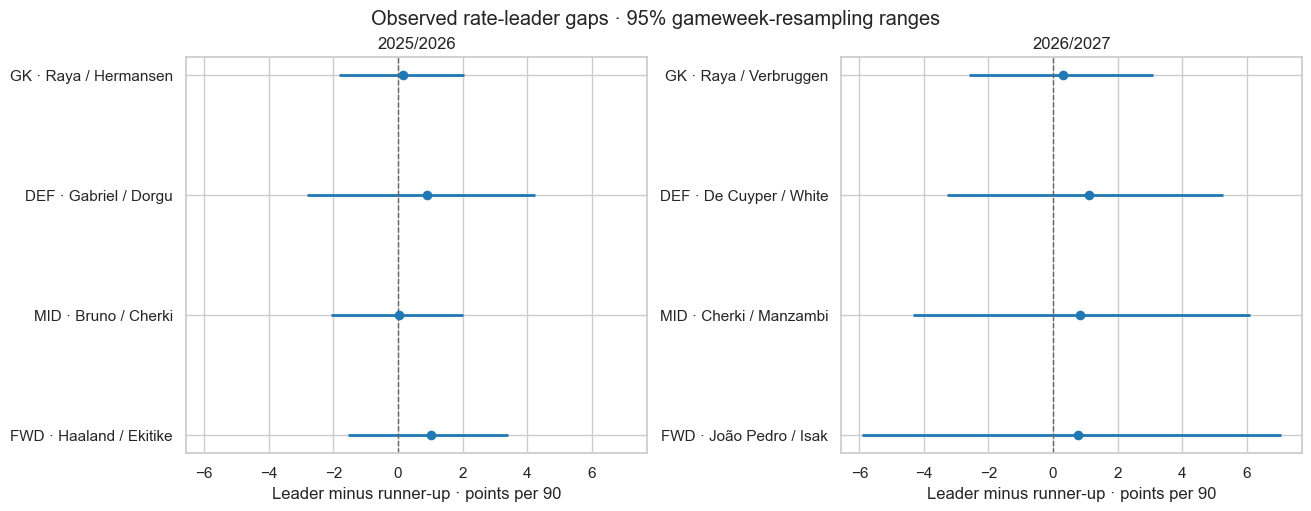

In [59]:
historical_rank_aliases = {**PRICE_LABEL_ALIASES, 1: "Raya", 679: "Hermansen", 441: "Dorgu"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, layout="constrained")
for ax, season in zip(axes, [BENCHMARK_SEASON, CURRENT_SEASON]):
    frame = ranking_leader_comparisons.loc[ranking_leader_comparisons.season.eq(season)]
    frame = frame.set_index("position").reindex(POSITION_ORDER).reset_index()
    aliases = historical_rank_aliases if season == BENCHMARK_SEASON else CURRENT_LABELS
    labels = [
        f"{position} · {aliases[first]} / {aliases[second]}"
        for position, first, second in frame[["position", "leader_id", "runner_up_id"]]
        .itertuples(index=False, name=None)
    ]
    y = np.arange(len(frame))
    ax.hlines(y, frame.gap_low, frame.gap_high, color="tab:blue", linewidth=2)
    ax.scatter(frame.observed_gap, y, color="tab:blue", s=35, zorder=3)
    ax.axvline(0, color=".4", linestyle="--", linewidth=1)
    ax.set_yticks(y, labels=labels)
    ax.invert_yaxis()
    ax.set(title=season.replace("_", "/"), xlabel="Leader minus runner-up · points per 90")
fig.suptitle("Observed rate-leader gaps · 95% gameweek-resampling ranges")
plt.show()

All eight leader-versus-runner-up gap ranges cross zero. For example, the 2025/26 midfielder
gap between Bruno and Cherki is only 0.044 points per 90; Bruno remains ahead in 51.2% of
retained draws. That is an unstable observed ordering, not evidence that their abilities are
equal. The current sample contains ten gameweeks rather than 38 and produces wider gap ranges.
Current goalkeeper and defender cohorts retain 1,993 and 1,998 draws; the other cohorts retain
all 2,000. Use broad performance groups and supporting role/exposure evidence rather than
presenting small adjacent-rank differences as settled conclusions.

## Save the EDA inputs

Write new typed tables and separate audits under `data/processed/`. Original source tables,
all defensive records and Notebook 1 remain unchanged. Re-running replaces only these EDA
outputs. The audit retains bridge evidence, lineup validation and the exact ICT mask.

In [60]:
eda_tables = {
    "player_matches": working_player_matches, "fixtures": working_fixtures,
    "teams": working_teams, "current_players": tables["current_players"],
    "current_events": tables["current_events"],
    "snapshot_metadata": tables["current_snapshot_metadata"],
    "player_profiles": profiles, "player_profiles_gw10": profiles_gw10,
    "team_matches": team_matches, "team_profiles": team_profiles,
    "historical_performance": historical_performance,
    "historical_point_summary": historical_point_summary,
    "historical_event_rates": historical_event_rates,
    "historical_point_sensitivity": point_source_sensitivity,
    "historical_associations": historical_associations,
    "rankings_2025_2026": benchmark_rankings,
    "regression_checks_2025_2026": regression_checks,
    "expected_actual_2025_2026": expected_actual_players,
    "historical_team_results": historical_team_matches,
    "historical_team_performance": historical_team_performance,
    "historical_team_venues": historical_team_venues,
    "historical_team_concentration": historical_team_concentration,
    "historical_player_team_stints": historical_player_team_stints,
    "historical_team_reference": historical_team_reference,
    "historical_season_components": historical_season_components,
    "historical_player_recurrence": historical_player_recurrence,
    "historical_team_patterns": historical_team_patterns,
    "current_player_progress": current_performance,
    "current_player_rankings": current_rankings,
    "current_recent_player_records": recent_current_records,
    "current_club_fixture_windows": current_club_windows,
    "current_expected_actual": current_expected_actual,
    "current_regression_checks": current_regression_checks,
    "current_window_comparison": current_window_comparison,
    "current_team_results": current_team_matches, "current_team_progress": current_team_report,
    "current_team_recent": current_teams["recent"],
    "current_team_venues": current_teams["venues"],
    "current_team_earlier": current_teams["earlier"],
    "current_opponent_context": current_opponent_context,
    "current_player_team_context": current_player_team_context,
    "ranking_stability_profiles": ranking_stability_profiles,
    "ranking_leader_comparisons": ranking_leader_comparisons,
}

In [61]:
eda_audits = {
    "start_repairs": start_repair["audit"], "start_validation": start_repair["validation"],
    "lineup_teams": start_repair["lineup_teams"], "ict_mask": ict_mask["audit"],
    "ict_gaps": ict_mask["gaps"], "season_coverage": season_coverage,
    "historical_point_components": historical_components,
    "point_component_residuals": component_review,
    "historical_expected_coverage": historical_expected_coverage,
    "historical_team_validation": historical_team_validation,
    "price_chart_labels": price_labels, "current_price_chart_labels": current_price_labels,
    "current_progress_validation": current_progress["validation"],
    "current_team_validation": current_teams["validation"],
    "ranking_resample_validation": ranking_resample_validation,
    "current_expected_coverage": current_expected_coverage,
    "current_goal_chart_labels": current_goal_labels,
    "current_assist_chart_labels": current_assist_labels,
    "team_logo_files": pd.DataFrame([
        {"season": season, "fpl_team_id": club, "path": str(path.relative_to(PROJECT_ROOT))}
        for season, paths in season_logo_files.items() for club, path in paths.items()
    ]),
    "goal_chart_labels": goal_labels, "assist_chart_labels": assist_labels,
    "defensive_count_disagreements": source_audits["defensive_count_disagreements"],
    "defensive_award_disagreements": source_audits["defensive_award_disagreements"],
    **{f"start_{name}_bridge": start_bridges[name] for name in ("teams", "fixtures", "players")},
}
pd.to_pickle(eda_tables, PROCESSED_DIR / "fpl_eda_tables.pkl")
pd.to_pickle(eda_audits, PROCESSED_DIR / "fpl_eda_audits.pkl")

### Provenance and final checks

Record input checksums, the repair rule and observed treatment counts. These files describe
the EDA copy; they do not replace Notebook 1's provenance or change its scoring policy.

In [62]:
manifest = {
    "schema_version": "fpl_eda_v5_synthesis_context",
    "prepared_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "source_schema": source_manifest["schema_version"], "input_sha256": source_hashes,
    "lineup_cache_sha256": sha256(FOTMOB_CACHE.read_bytes()).hexdigest(),
    "code_sha256": {
        name: sha256((PROJECT_ROOT / "src" / name).read_bytes()).hexdigest()
        for name in ("eda_preparation.py", "fotmob_identity.py",
                     "data_preparation.py", "player_analysis.py",
                     "defensive_contributions.py", "team_analysis.py", "plot_annotations.py",
                     "current_player_analysis.py", "analysis_synthesis.py",
                     "current_team_analysis.py", "ranking_uncertainty.py")
    },
    "analysis_scope": "historical recurrence, captured player/team context, ranking stability",
    "ranking_resampling": {"unit": "shared gameweek", "draws": BOOTSTRAP_DRAWS,
                           "seed": BOOTSTRAP_SEED, "interval": "95% percentile",
                           "cohort": "fixed observed position cohorts"},
    "opponent_context_policy": "strictly earlier current-season matches; 3 measured priors",
    "current_window_policy": "last five completed current-club fixtures; missing rows unknown",
    "logo_policy": "logos/ only; all historical and current clubs",
    "logo_sha256": {
        str(path.relative_to(PROJECT_ROOT)): sha256(path.read_bytes()).hexdigest()
        for path in sorted({path for paths in season_logo_files.values()
                            for path in paths.values()})
    },
    "team_points_policy": "results-based 3W+D; no administrative deductions",
    "team_expected_policy": "player xG once per fixture; xGA from opponent team xG",
    "component_rule": COMPONENT_RULE,
    "component_residual_rows": len(component_review),
    "historical_expected_gap_fixtures": int(
        historical_expected_coverage.suspect_zero_block.sum()
    ),
    "start_rule": "explicit_lineup_v1_preserve_source_starts",
    "corrected_starts": int(start_repair["audit"].changed.sum()),
    "ict_masked_cells": len(ict_mask["audit"]) * len(ICT_FIELDS),
    "defensive_records": "preserved without filtering or recalculation",
    "tables": {name: {"rows": len(frame), "columns": len(frame.columns)}
               for name, frame in eda_tables.items()},
}
(PROCESSED_DIR / "fpl_eda_manifest.json").write_text(json.dumps(manifest, indent=2))
assert source_hashes == {
    path.name: sha256(path.read_bytes()).hexdigest() for path in input_paths
}
display(pd.DataFrame(manifest["tables"]).T)

,rows,columns
player_matches,119822,62
fixtures,1900,20
teams,100,4
current_players,672,112
current_events,38,32
snapshot_metadata,1,13
player_profiles,3940,24
player_profiles_gw10,3465,24
team_matches,3240,17
team_profiles,100,7


## Ready for further analysis

The working copy retains all 119,822 player-fixture records and the original defensive
fields. Original source tables remain unchanged; starter repairs and the selective ICT
mask are audited. Historical recurrence, separate current player/team progress and
conditional ranking-stability summaries are exported with their validation and provenance.

Later models should use lagged features, chronological splits and validation appropriate
to their targets. The current notebook supplies descriptive evidence and contextual
variables; it does not establish causal feature importance, calibrated availability
probabilities or future player ability. Use the findings at the top as the short reading
route and retain the technical checks as supporting evidence.